### Raw-column index

Click a variable below to jump to its rendered report.

**Identity and classification:** [id](#raw-eda-id) · [stmt_date](#raw-eda-stmt-date) · [HQ_city](#raw-eda-hq-city) · [legal_struct](#raw-eda-legal-struct) · [ateco_sector](#raw-eda-ateco-sector) · [def_date](#raw-eda-def-date) · [fs_year](#raw-eda-fs-year)

**Assets:** [asst_intang_fixed](#raw-eda-asst-intang-fixed) · [asst_tang_fixed](#raw-eda-asst-tang-fixed) · [asst_fixed_fin](#raw-eda-asst-fixed-fin) · [asst_current](#raw-eda-asst-current) · [AR](#raw-eda-ar) · [cash_and_equiv](#raw-eda-cash-and-equiv) · [asst_tot](#raw-eda-asst-tot)

**Equity and liabilities:** [eqty_tot](#raw-eda-eqty-tot) · [eqty_corp_family_tot](#raw-eda-eqty-corp-family-tot) · [liab_lt](#raw-eda-liab-lt) · [liab_lt_emp](#raw-eda-liab-lt-emp) · [debt_bank_st](#raw-eda-debt-bank-st) · [debt_bank_lt](#raw-eda-debt-bank-lt) · [debt_fin_st](#raw-eda-debt-fin-st) · [debt_fin_lt](#raw-eda-debt-fin-lt) · [AP_st](#raw-eda-ap-st) · [AP_lt](#raw-eda-ap-lt) · [debt_st](#raw-eda-debt-st) · [debt_lt](#raw-eda-debt-lt)

**Income statement:** [rev_operating](#raw-eda-rev-operating) · [COGS](#raw-eda-cogs) · [prof_operations](#raw-eda-prof-operations) · [goodwill](#raw-eda-goodwill) · [inc_financing](#raw-eda-inc-financing) · [exp_financing](#raw-eda-exp-financing) · [prof_financing](#raw-eda-prof-financing) · [inc_extraord](#raw-eda-inc-extraord) · [taxes](#raw-eda-taxes) · [profit](#raw-eda-profit) · [ebitda](#raw-eda-ebitda)

**Other financial measures:** [days_rec](#raw-eda-days-rec) · [roa](#raw-eda-roa) · [roe](#raw-eda-roe) · [wc_net](#raw-eda-wc-net) · [margin_fin](#raw-eda-margin-fin) · [cf_operations](#raw-eda-cf-operations)

In [1]:
import pandas as pd
data = pd.read_csv(
    r"/Users/yuxin/Documents/NYU DS/NYU-DS/2026 Fall/ML in Finance/Project/codebase/finance_term_project/data/raw/train-2025.csv",
    low_memory=False,
).drop(columns=["Unnamed: 0"], errors="ignore")

# Keep this list before adding region/province lookup columns later in the notebook.
RAW_COLUMNS = data.columns.tolist()

### Understanding the Raw columns

#### Sample Analysis

In [13]:
data[(data["fs_year"]==2012) & (data["def_date"].isna()==False)][["id", "stmt_date", "def_date"]].sort_values(by = "def_date", ascending=False).head(10)

,id,stmt_date,def_date
997329,122700255,2012-12-31,2013-05-31
998074,375510526,2012-12-31,2013-05-31
999103,908090525,2012-12-31,2013-05-31
1006811,2920610611,2012-12-31,2013-05-31
1009562,4116490261,2012-12-31,2013-05-31
997517,171550544,2012-12-31,2013-05-30
998170,444630487,2012-12-31,2013-05-30
1000944,1401800063,2012-12-31,2013-05-30
1001823,1595140979,2012-12-31,2013-05-30
1001873,1608880447,2012-12-31,2013-05-30


In [3]:
data.groupby(["fs_year"]).agg(n_companies=("id", "count"))

,n_companies
fs_year,
2007,144528
2008,161863
2009,171150
2010,175399
2011,184973
2012,185639


In [4]:
company_record_distribution = (
    data.groupby("id")
    .size()
    .value_counts()
    .sort_index()
    .rename_axis("n_yearly_records")
    .reset_index(name="n_companies")
)

company_record_distribution

,n_yearly_records,n_companies
0,1,29963
1,2,25870
2,3,23149
3,4,22412
4,5,35148
5,6,101169


#### HQ_city

In [5]:
len(data['HQ_city'].dropna().drop_duplicates())

110

In [2]:
region_group = pd.read_csv(r"/Users/yuxin/Documents/NYU DS/NYU-DS/2026 Fall/ML in Finance/Project/codebase/finance_term_project/data/interim/HQ_city_code_to_province_region.csv")

In [3]:
data["HQ_city"] = pd.to_numeric(data["HQ_city"])
data = pd.merge(data, region_group, how="left", left_on="HQ_city", right_on="HQ_city")
data

,id,stmt_date,HQ_city,legal_struct,ateco_sector,def_date,fs_year,asst_intang_fixed,asst_tang_fixed,asst_fixed_fin,...,days_rec,ebitda,roa,roe,wc_net,margin_fin,cf_operations,province,region,region_code
0,520288,2011-12-31,28.0,SRL,14.0,NaN,2011,67537.0,1137566.0,1908.0,...,NaN,6318.0,-3.81,-28.03,496258.0,-917029.0,-849.0,PADOVA,Veneto,5.0
1,520288,2008-12-31,28.0,SRL,14.0,NaN,2008,256438.0,1181416.0,860.0,...,NaN,46088.0,-2.76,NaN,97952.0,NaN,-3881.0,PADOVA,Veneto,5.0
2,520288,2009-12-31,28.0,SRL,14.0,NaN,2009,194046.0,1152014.0,860.0,...,NaN,67611.0,-2.17,NaN,-210671.0,NaN,32618.0,PADOVA,Veneto,5.0
3,520288,2012-12-31,28.0,SRL,14.0,NaN,2012,15195.0,1116938.0,2023.0,...,NaN,-161478.0,-12.99,NaN,367892.0,-1094962.0,-168907.0,PADOVA,Veneto,5.0
4,520288,2007-12-31,28.0,SRL,14.0,NaN,2007,126603.0,1127807.0,620.0,...,NaN,153060.0,6.20,52.43,-317007.0,-1184970.0,80039.0,PADOVA,Veneto,5.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1023547,92001230520,2011-12-31,52.0,SPA,93.0,NaN,2011,1498628.0,248233.0,163477.0,...,-15.33,984567.0,2.16,-43.00,204689.0,-1286111.0,550755.0,SIENA,Toscana,9.0
1023548,92001230520,2008-12-31,52.0,SPA,93.0,NaN,2008,2465065.0,343015.0,43477.0,...,23.01,1746442.0,12.97,1.01,-472335.0,-2212557.0,945705.0,SIENA,Toscana,9.0
1023549,92001230520,2007-12-31,52.0,SPA,93.0,NaN,2007,2375606.0,261775.0,28642.0,...,33.64,1539957.0,6.15,0.62,-78424.0,-2033489.0,1166064.0,SIENA,Toscana,9.0
1023550,94111750108,2010-12-31,10.0,SRL,68.0,NaN,2010,2973.0,1131586.0,264600.0,...,NaN,-4795.0,-0.31,-1.85,148203.0,-1140392.0,-4793.0,GENOVA,Liguria,7.0


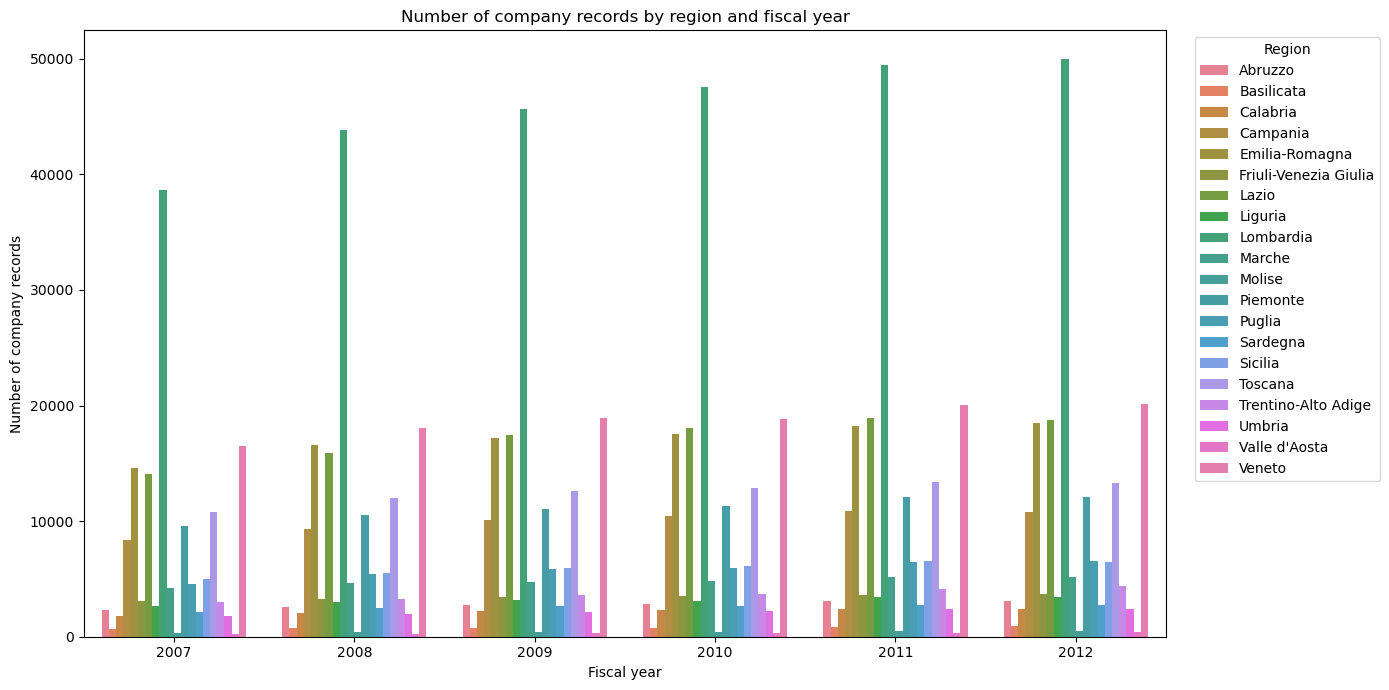

In [8]:
import seaborn as sns
import matplotlib.pyplot as plt

data.groupby(["region", "fs_year"]).agg(n_companies=("id", "count"))

company_counts = (
    data.groupby(["region", "fs_year"])
    .agg(n_companies=("id", "count"))
    .reset_index()
)

plt.figure(figsize=(14, 7))
sns.barplot(
    data=company_counts,
    x="fs_year",
    y="n_companies",
    hue="region",
    errorbar=None,
)

plt.title("Number of company records by region and fiscal year")
plt.xlabel("Fiscal year")
plt.ylabel("Number of company records")
plt.legend(title="Region", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

## Complete raw-column EDA

Run the next two cells after loading `data`. They report every original raw column in English. Anomaly counts reproduce the rules in `01_flag_anomalies.ipynb`. For continuous financial variables, an outlier is a finite value outside the modified Tukey fences based on the 20th and 80th percentiles: `p20 - 1.5 × (p80 - p20)` or `p80 + 1.5 × (p80 - p20)`. The box plot uses that requested 20%–80% box. Identifiers, dates, and category codes are not assigned numerical outlier counts.

The final optional section provides one additional diagnostic for continuous variables: their median and missingness rate by fiscal year.

In [65]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from IPython.display import HTML, Markdown, display

# Work only with the columns present in the initially loaded raw file.
raw_data = data.loc[:, RAW_COLUMNS].copy()

DEBT_DETAIL = ["debt_bank_st", "debt_bank_lt", "debt_fin_st", "debt_fin_lt", "AP_st", "AP_lt"]
NEG_BS_COLS = [
    "asst_intang_fixed", "asst_tang_fixed", "asst_fixed_fin", "AR",
    "liab_lt", "liab_lt_emp", *DEBT_DETAIL, "debt_st", "debt_lt",
]

# Per-column anomaly masks mirror the existing project anomaly definitions.
def make_column_anomaly_masks(frame):
    masks = {column: pd.Series(False, index=frame.index) for column in frame.columns}
    numeric_columns = [
        *NEG_BS_COLS, "rev_operating", "COGS", "exp_financing", "ebitda",
        "prof_operations", "prof_financing", "goodwill",
    ]
    values = frame.reindex(columns=numeric_columns).apply(pd.to_numeric, errors="coerce")

    for column in set(NEG_BS_COLS).intersection(masks):
        masks[column] |= values[column].lt(0)
    for column in ["rev_operating", "COGS", "exp_financing"]:
        if column in masks:
            masks[column] |= values[column].lt(0)
    if "goodwill" in masks:
        masks["goodwill"] |= values["goodwill"].lt(0)
    if "prof_financing" in masks:
        masks["prof_financing"] |= values["prof_financing"].notna() & values["prof_financing"].ne(0)

    ebitda_inconsistent = values["ebitda"].lt(values["prof_operations"])
    for column in ["ebitda", "prof_operations"]:
        if column in masks:
            masks[column] |= ebitda_inconsistent

    short_detail = values["debt_bank_st"] + values["debt_fin_st"] + values["AP_st"]
    long_detail = values["debt_bank_lt"] + values["debt_fin_lt"] + values["AP_lt"]
    detail_complete = values[DEBT_DETAIL].notna().all(axis=1)
    short_inconsistent = detail_complete & short_detail.gt(values["debt_st"] + 1)
    long_inconsistent = detail_complete & long_detail.gt(values["debt_lt"] + 1)
    for column in ["debt_bank_st", "debt_fin_st", "AP_st", "debt_st"]:
        if column in masks:
            masks[column] |= short_inconsistent
    for column in ["debt_bank_lt", "debt_fin_lt", "AP_lt", "debt_lt"]:
        if column in masks:
            masks[column] |= long_inconsistent
    return masks

COLUMN_ANOMALIES = make_column_anomaly_masks(raw_data)
DATE_COLUMNS = {"stmt_date", "def_date", "pred_start_dt"}
CATEGORY_COLUMNS = {"id", "HQ_city", "legal_struct", "ateco_sector", "fs_year", "label"}

def continuous_values(series):
    return pd.to_numeric(series, errors="coerce").replace([np.inf, -np.inf], np.nan)

def modified_tukey_outliers(values):
    values = values.dropna()
    if values.nunique() < 2:
        return pd.Series(False, index=values.index), (np.nan, np.nan)
    p20, p80 = values.quantile([0.20, 0.80])
    spread = p80 - p20
    lower, upper = p20 - 1.5 * spread, p80 + 1.5 * spread
    return (values.lt(lower) | values.gt(upper)), (lower, upper)

def raw_eda_summary(column):
    series = raw_data[column]
    n_missing = int(series.isna().sum())
    n_anomalies = int(COLUMN_ANOMALIES[column].sum())
    if column in DATE_COLUMNS or column in CATEGORY_COLUMNS:
        n_outliers = "N/A"
    else:
        outlier_mask, _ = modified_tukey_outliers(continuous_values(series))
        n_outliers = int(outlier_mask.sum())
    return pd.DataFrame({
        "variable": [column],
        "n_missing": [n_missing],
        "pct_missing": [round(100 * n_missing / len(raw_data), 2)],
        "n_anomalies": [n_anomalies],
        "n_outliers": [n_outliers],
    })

def numerical_summary(series, column):
    values = continuous_values(series).dropna()
    mode = values.mode()
    return pd.DataFrame({
        "variable": [column],
        "mean": [values.mean()], "mode": [mode.iloc[0] if not mode.empty else np.nan],
        "std": [values.std()], "min": [values.min()],
        "p10": [values.quantile(0.10)], "p20": [values.quantile(0.20)],
        "p25": [values.quantile(0.25)], "median": [values.median()],
        "p75": [values.quantile(0.75)], "p80": [values.quantile(0.80)],
        "p90": [values.quantile(0.90)], "max": [values.max()],
    }).round(4)

def categorical_summary(series, column):
    observed = series.dropna()
    mode = observed.mode()
    return pd.DataFrame({
        "variable": [column], "n_observed": [len(observed)],
        "n_unique": [observed.nunique()],
        "mode": [mode.iloc[0] if not mode.empty else np.nan],
        "mode_count": [int(observed.eq(mode.iloc[0]).sum()) if not mode.empty else 0],
    })

def plot_continuous_variable(series, column):
    values = continuous_values(series).dropna()
    if values.empty:
        print("No observed numeric values to plot.")
        return
    p01, p99 = values.quantile([0.01, 0.99])
    shown = values.clip(p01, p99)
    outlier_mask, (lower, upper) = modified_tukey_outliers(values)
    p20, median, p80 = values.quantile([0.20, 0.50, 0.80])

    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    sns.histplot(shown, bins=40, ax=axes[0], color="#4C78A8")
    axes[0].set_title(f"Empirical distribution: {column}")
    axes[0].set_xlabel(f"{column} (display clipped to p1–p99)")
    axes[0].set_ylabel("Number of records")

    inliers = values[~outlier_mask]
    axes[1].bxp([{
        "label": column, "whislo": inliers.min(), "q1": p20, "med": median,
        "q3": p80, "whishi": inliers.max(),
        "fliers": values[outlier_mask].sample(min(1_000, int(outlier_mask.sum())), random_state=42).tolist(),
    }], showfliers=True)
    axes[1].set_title(f"20th–80th percentile box plot: {column}")
    axes[1].set_ylabel(column)
    plt.tight_layout()
    plt.show()
    print(f"Display histogram is clipped to p1–p99; modified-Tukey outlier fences: [{lower:,.4g}, {upper:,.4g}].")

def plot_categorical_variable(series, column):
    if column in DATE_COLUMNS:
        values = pd.to_datetime(series, errors="coerce").dt.year
        xlabel = "Year"
    else:
        values = series.astype("string")
        xlabel = column
    counts = values.value_counts(dropna=False).head(20).sort_values()
    plt.figure(figsize=(10, max(4, 0.32 * len(counts))))
    sns.barplot(x=counts.values, y=counts.index.astype(str), color="#4C78A8")
    plt.title(f"Empirical distribution: {column} (top 20 categories)")
    plt.xlabel("Number of records")
    plt.ylabel(xlabel)
    plt.tight_layout()
    plt.show()

def _column_anchor(column):
    return column.lower().replace("_", "-")

def show_raw_column_eda(column, show_yearly_diagnostic=True):
    anchor = _column_anchor(column)
    display(HTML(f'<a id="raw-eda-{anchor}"></a><h3>{column}</h3>'))
    display(Markdown("**1. Missing values, anomalies, and outliers**"))
    display(raw_eda_summary(column))
    display(Markdown("**2. Summary statistics**"))
    if column in DATE_COLUMNS or column in CATEGORY_COLUMNS:
        display(categorical_summary(raw_data[column], column))
        display(Markdown("Mean, standard deviation, percentiles, and numerical outliers are not meaningful for this identifier, date, or categorical code."))
        display(Markdown("**3. Empirical distribution**"))
        plot_categorical_variable(raw_data[column], column)
    else:
        display(numerical_summary(raw_data[column], column))
        display(Markdown("**3–4. Empirical distribution and 20th–80th percentile box plot**"))
        plot_continuous_variable(raw_data[column], column)
        if show_yearly_diagnostic and "fs_year" in raw_data:
            display(Markdown("**5. Additional diagnostic: median and missingness by fiscal year**"))
            yearly = raw_data.groupby("fs_year")[column].agg(
                n_observed=lambda x: x.notna().sum(),
                pct_missing=lambda x: round(100 * x.isna().mean(), 2),
                median=lambda x: continuous_values(x).median(),
            )
            display(yearly.round(4))


**1. Missing values, anomalies, and outliers**

,variable,n_missing,pct_missing,n_anomalies,n_outliers
0,id,0,0.0,0,N/A


**2. Summary statistics**

,variable,n_observed,n_unique,mode,mode_count
0,id,1023552,237711,520288,6


Mean, standard deviation, percentiles, and numerical outliers are not meaningful for this identifier, date, or categorical code.

**3. Empirical distribution**

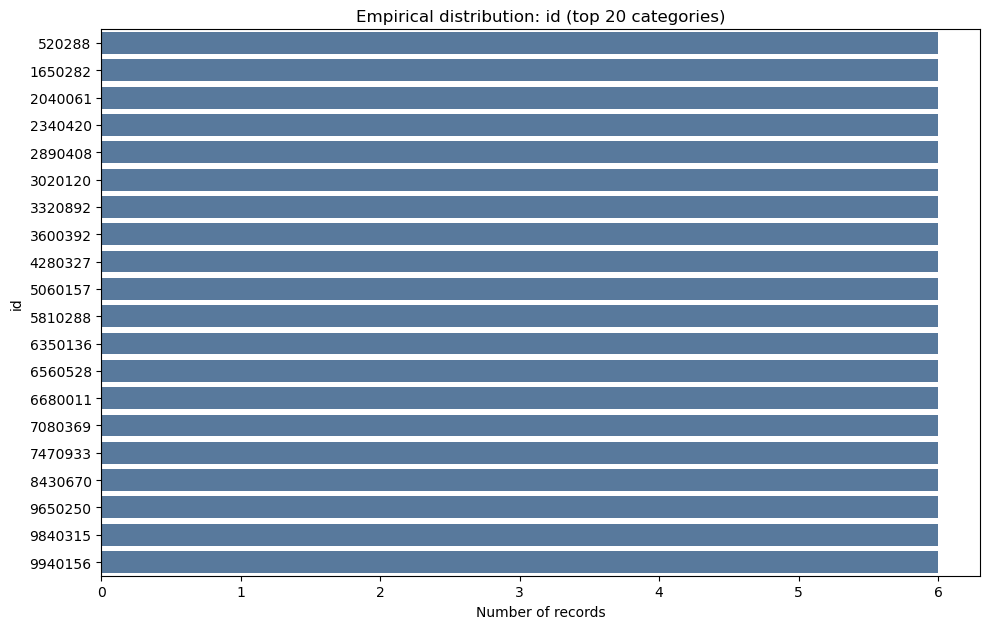

**1. Missing values, anomalies, and outliers**

,variable,n_missing,pct_missing,n_anomalies,n_outliers
0,stmt_date,0,0.0,0,N/A


**2. Summary statistics**

,variable,n_observed,n_unique,mode,mode_count
0,stmt_date,1023552,6,2012-12-31,185639


Mean, standard deviation, percentiles, and numerical outliers are not meaningful for this identifier, date, or categorical code.

**3. Empirical distribution**

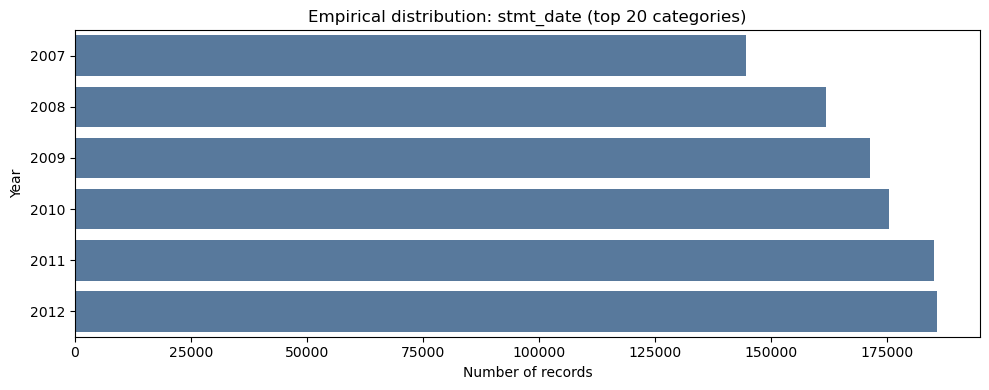

**1. Missing values, anomalies, and outliers**

,variable,n_missing,pct_missing,n_anomalies,n_outliers
0,HQ_city,277,0.03,0,N/A


**2. Summary statistics**

,variable,n_observed,n_unique,mode,mode_count
0,HQ_city,1023275,110,15.0,122090


Mean, standard deviation, percentiles, and numerical outliers are not meaningful for this identifier, date, or categorical code.

**3. Empirical distribution**

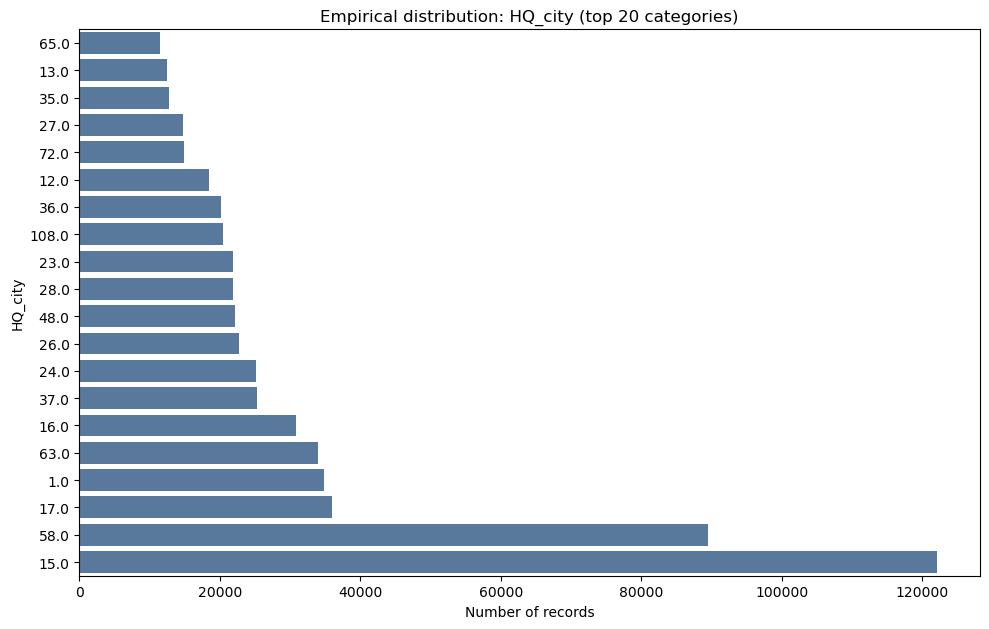

**1. Missing values, anomalies, and outliers**

,variable,n_missing,pct_missing,n_anomalies,n_outliers
0,legal_struct,0,0.0,0,N/A


**2. Summary statistics**

,variable,n_observed,n_unique,mode,mode_count
0,legal_struct,1023552,6,SRL,738994


Mean, standard deviation, percentiles, and numerical outliers are not meaningful for this identifier, date, or categorical code.

**3. Empirical distribution**

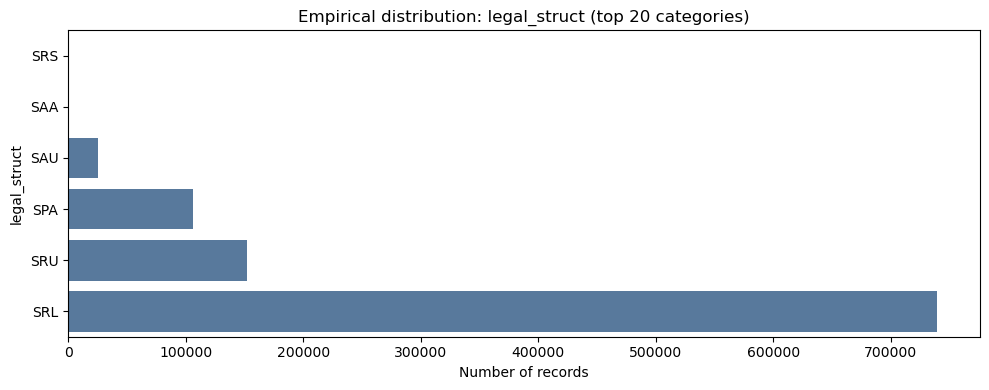

**1. Missing values, anomalies, and outliers**

,variable,n_missing,pct_missing,n_anomalies,n_outliers
0,ateco_sector,0,0.0,0,N/A


**2. Summary statistics**

,variable,n_observed,n_unique,mode,mode_count
0,ateco_sector,1023552,83,68.0,199387


Mean, standard deviation, percentiles, and numerical outliers are not meaningful for this identifier, date, or categorical code.

**3. Empirical distribution**

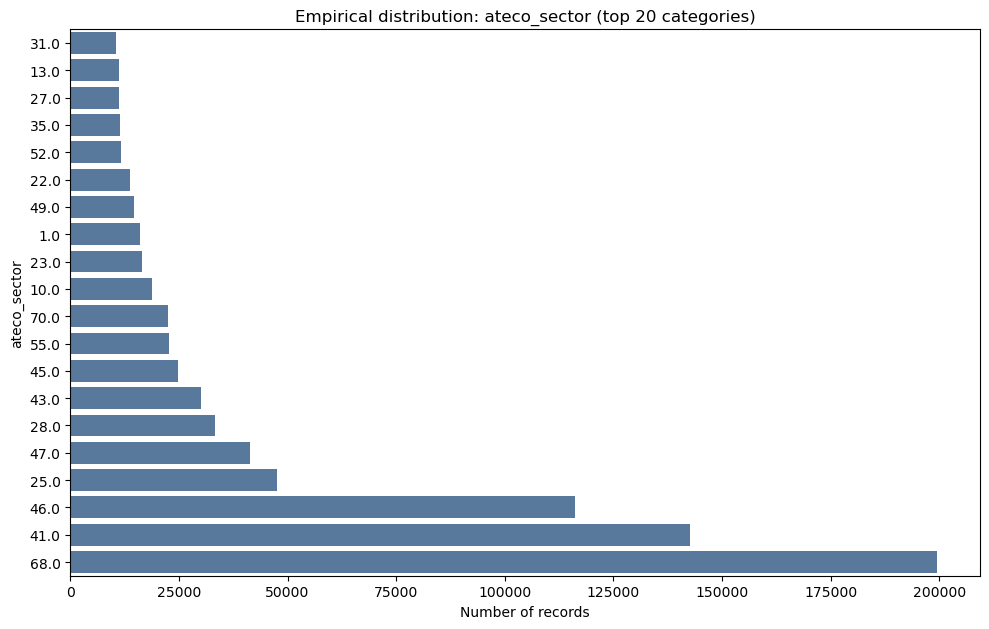

**1. Missing values, anomalies, and outliers**

,variable,n_missing,pct_missing,n_anomalies,n_outliers
0,def_date,978827,95.63,0,N/A


**2. Summary statistics**

,variable,n_observed,n_unique,mode,mode_count
0,def_date,44725,1467,2012-12-20,288


Mean, standard deviation, percentiles, and numerical outliers are not meaningful for this identifier, date, or categorical code.

**3. Empirical distribution**

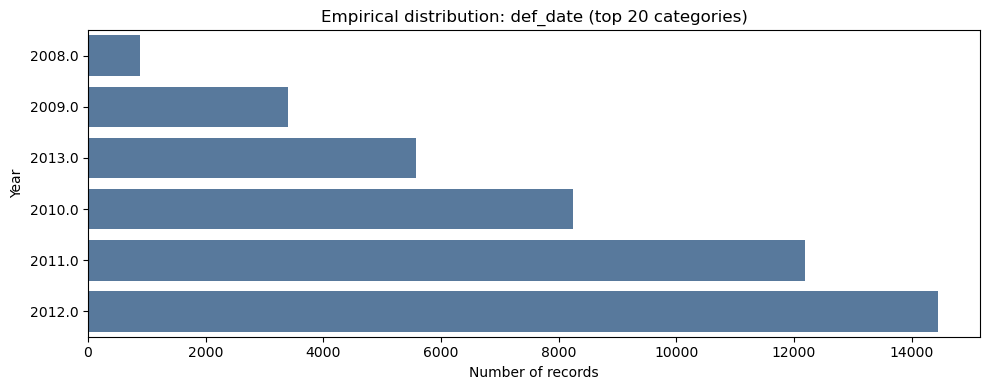

**1. Missing values, anomalies, and outliers**

,variable,n_missing,pct_missing,n_anomalies,n_outliers
0,fs_year,0,0.0,0,N/A


**2. Summary statistics**

,variable,n_observed,n_unique,mode,mode_count
0,fs_year,1023552,6,2012,185639


Mean, standard deviation, percentiles, and numerical outliers are not meaningful for this identifier, date, or categorical code.

**3. Empirical distribution**

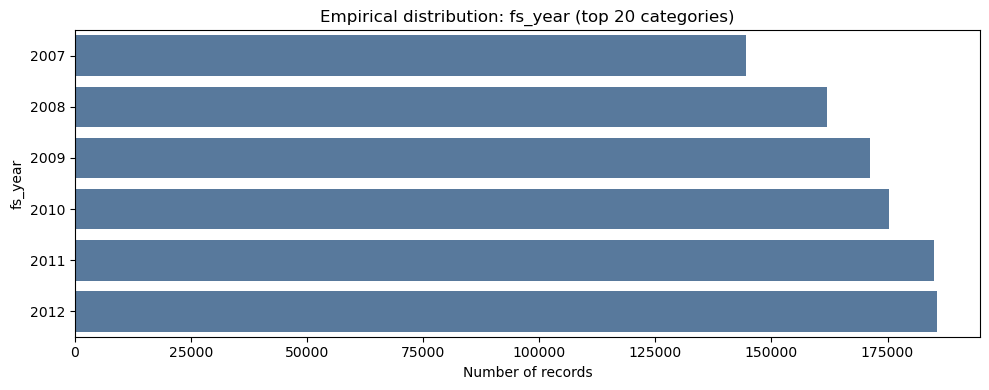

**1. Missing values, anomalies, and outliers**

,variable,n_missing,pct_missing,n_anomalies,n_outliers
0,asst_intang_fixed,162,0.02,799,117998


**2. Summary statistics**

,variable,mean,mode,std,min,p10,p20,p25,median,p75,p80,p90,max
0,asst_intang_fixed,468404.7429,0.0,1.486886e+07,-3442959.0,0.0,0.0,262.0,7975.0,75156.75,119836.0,364399.1,3.708467e+09


**3–4. Empirical distribution and 20th–80th percentile box plot**

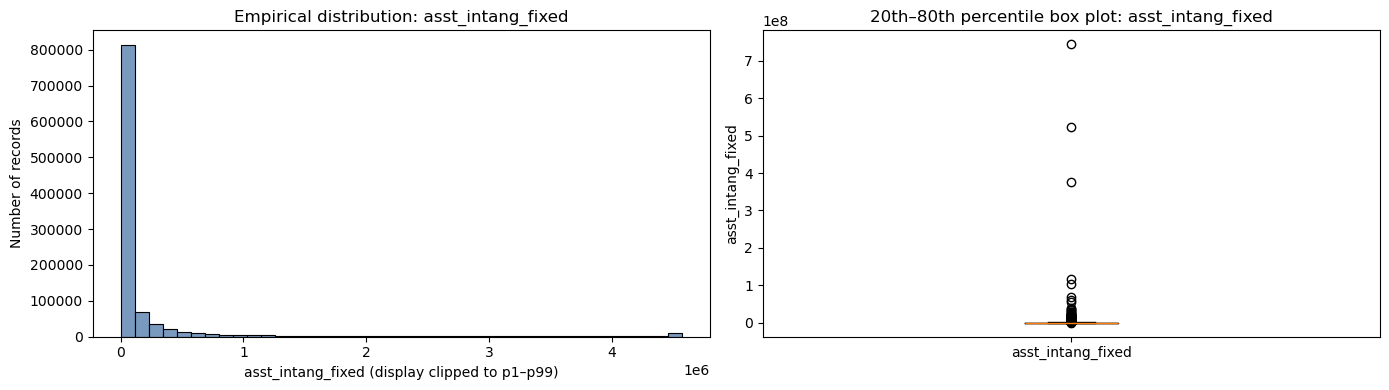

Display histogram is clipped to p1–p99; modified-Tukey outlier fences: [-1.798e+05, 2.996e+05].


**5. Additional diagnostic: median and missingness by fiscal year**

,n_observed,pct_missing,median
fs_year,,,
2007,144509,0.01,9550.0
2008,161831,0.02,8253.0
2009,171040,0.06,7793.0
2010,175398,0.00,7473.0
2011,184973,0.00,7545.0
2012,185639,0.00,7540.0


**1. Missing values, anomalies, and outliers**

,variable,n_missing,pct_missing,n_anomalies,n_outliers
0,asst_tang_fixed,103,0.01,318,77514


**2. Summary statistics**

,variable,mean,mode,std,min,p10,p20,p25,median,p75,p80,p90,max
0,asst_tang_fixed,3.411074e+06,0.0,1.293634e+08,-1711468.0,210.0,34411.6,66631.0,595899.0,2064874.0,2636963.4,5126046.4,5.822144e+10


**3–4. Empirical distribution and 20th–80th percentile box plot**

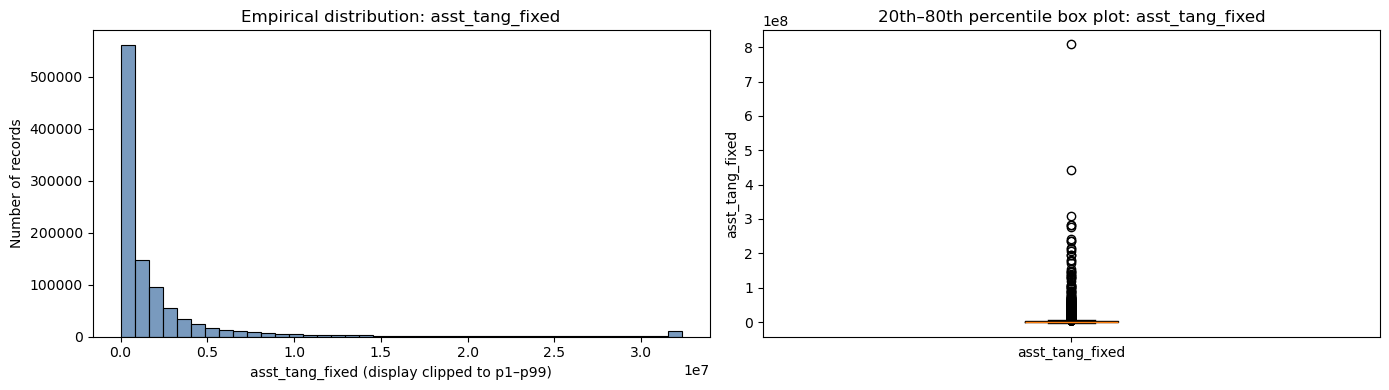

Display histogram is clipped to p1–p99; modified-Tukey outlier fences: [-3.869e+06, 6.541e+06].


**5. Additional diagnostic: median and missingness by fiscal year**

,n_observed,pct_missing,median
fs_year,,,
2007,144509,0.01,462888.0
2008,161832,0.02,611721.0
2009,171099,0.03,630934.0
2010,175397,0.00,615170.0
2011,184973,0.00,620871.0
2012,185639,0.00,647328.0


**1. Missing values, anomalies, and outliers**

,variable,n_missing,pct_missing,n_anomalies,n_outliers
0,asst_fixed_fin,237,0.02,1285,149505


**2. Summary statistics**

,variable,mean,mode,std,min,p10,p20,p25,median,p75,p80,p90,max
0,asst_fixed_fin,1.171699e+06,0.0,2.875413e+07,-2490262.0,0.0,0.0,0.0,1378.0,71881.0,163477.0,940010.0,8.529187e+09


**3–4. Empirical distribution and 20th–80th percentile box plot**

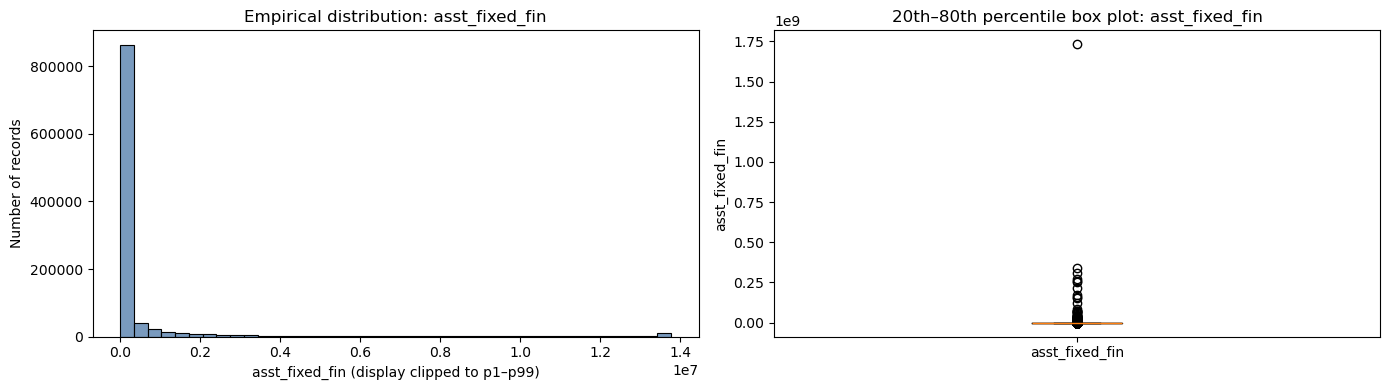

Display histogram is clipped to p1–p99; modified-Tukey outlier fences: [-2.452e+05, 4.087e+05].


**5. Additional diagnostic: median and missingness by fiscal year**

,n_observed,pct_missing,median
fs_year,,,
2007,144509,0.01,1453.0
2008,161830,0.02,1142.0
2009,170971,0.10,1192.0
2010,175393,0.00,1321.0
2011,184973,0.00,1473.0
2012,185639,0.00,1744.0


**1. Missing values, anomalies, and outliers**

,variable,n_missing,pct_missing,n_anomalies,n_outliers
0,asst_current,1,0.0,0,79869


**2. Summary statistics**

,variable,mean,mode,std,min,p10,p20,p25,median,p75,p80,p90,max
0,asst_current,5.957970e+06,2318938.0,5.419817e+07,0.0,255913.0,786736.0,1072830.0,2040524.0,4135408.0,5095603.0,9411945.0,1.479057e+10


**3–4. Empirical distribution and 20th–80th percentile box plot**

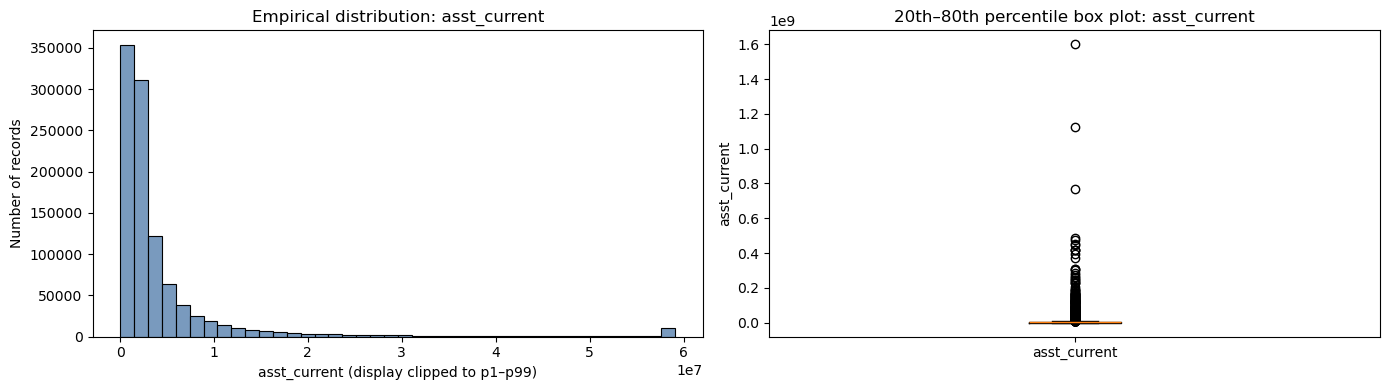

Display histogram is clipped to p1–p99; modified-Tukey outlier fences: [-5.677e+06, 1.156e+07].


**5. Additional diagnostic: median and missingness by fiscal year**

,n_observed,pct_missing,median
fs_year,,,
2007,144528,0.0,2202749.0
2008,161862,0.0,2067421.0
2009,171150,0.0,2013765.0
2010,175399,0.0,2018708.0
2011,184973,0.0,2000570.0
2012,185639,0.0,1981387.0


**1. Missing values, anomalies, and outliers**

,variable,n_missing,pct_missing,n_anomalies,n_outliers
0,AR,12,0.0,534,79616


**2. Summary statistics**

,variable,mean,mode,std,min,p10,p20,p25,median,p75,p80,p90,max
0,AR,3.360637e+06,0.0,3.994736e+07,-2782518.0,55821.7,158110.8,234072.75,891695.5,2092540.25,2619158.0,5036200.2,1.101077e+10


**3–4. Empirical distribution and 20th–80th percentile box plot**

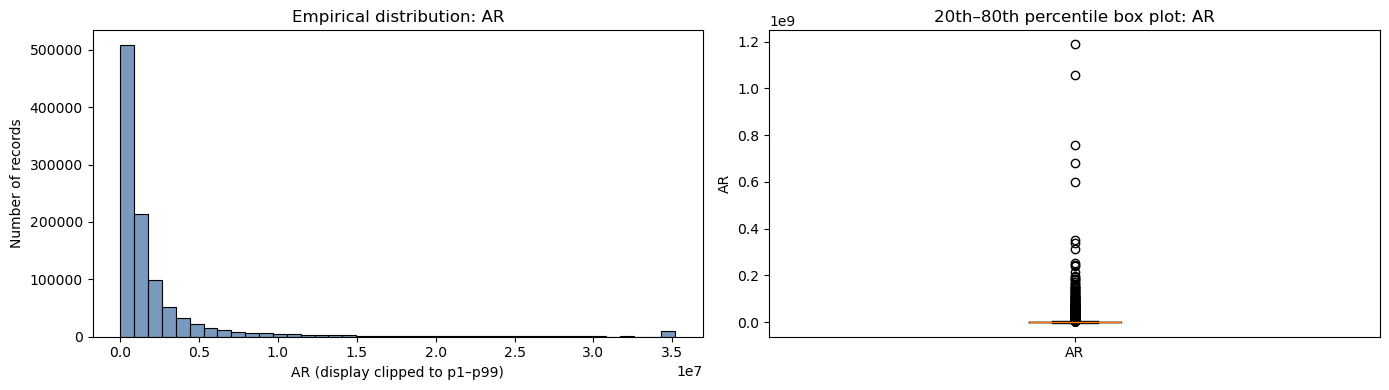

Display histogram is clipped to p1–p99; modified-Tukey outlier fences: [-3.533e+06, 6.311e+06].


**5. Additional diagnostic: median and missingness by fiscal year**

,n_observed,pct_missing,median
fs_year,,,
2007,144528,0.00,1020118.0
2008,161851,0.01,909685.0
2009,171150,0.00,846578.5
2010,175399,0.00,860405.0
2011,184973,0.00,870997.0
2012,185639,0.00,866398.0


**1. Missing values, anomalies, and outliers**

,variable,n_missing,pct_missing,n_anomalies,n_outliers
0,cash_and_equiv,17,0.0,0,92698


**2. Summary statistics**

,variable,mean,mode,std,min,p10,p20,p25,median,p75,p80,p90,max
0,cash_and_equiv,475114.6146,0.0,9.391475e+06,-25845931.0,827.0,3642.0,6223.0,49647.0,262875.5,368972.0,828749.2,5.519622e+09


**3–4. Empirical distribution and 20th–80th percentile box plot**

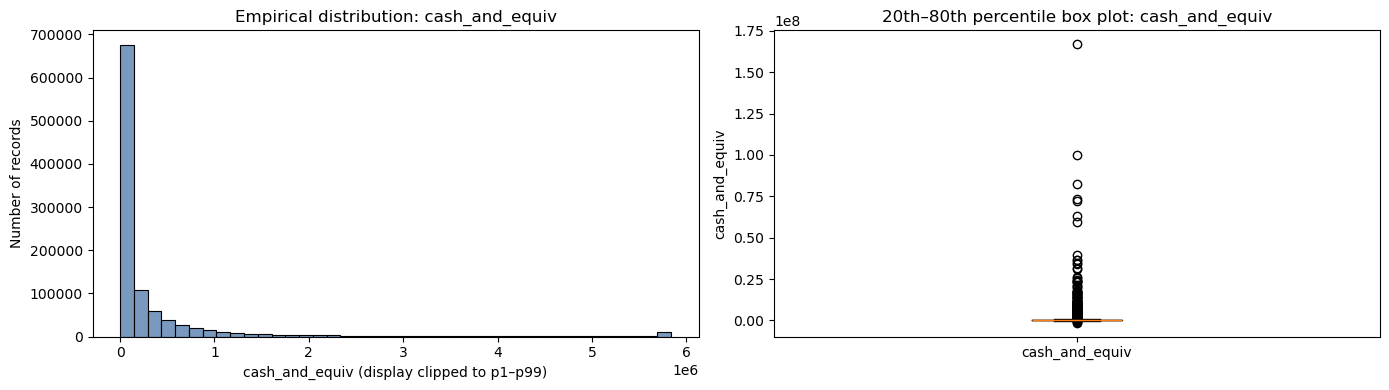

Display histogram is clipped to p1–p99; modified-Tukey outlier fences: [-5.444e+05, 9.17e+05].


**5. Additional diagnostic: median and missingness by fiscal year**

,n_observed,pct_missing,median
fs_year,,,
2007,144528,0.00,67740.0
2008,161851,0.01,49301.0
2009,171147,0.00,49410.0
2010,175399,0.00,49290.0
2011,184971,0.00,46859.0
2012,185639,0.00,41589.0


**1. Missing values, anomalies, and outliers**

,variable,n_missing,pct_missing,n_anomalies,n_outliers
0,asst_tot,0,0.0,0,85240


**2. Summary statistics**

,variable,mean,mode,std,min,p10,p20,p25,median,p75,p80,p90,max
0,asst_tot,1.111351e+07,2451176.0,1.799274e+08,1500000.0,1724310.2,2003208.2,2170073.0,3458428.5,6975953.25,8605203.2,15854946.2,7.164463e+10


**3–4. Empirical distribution and 20th–80th percentile box plot**

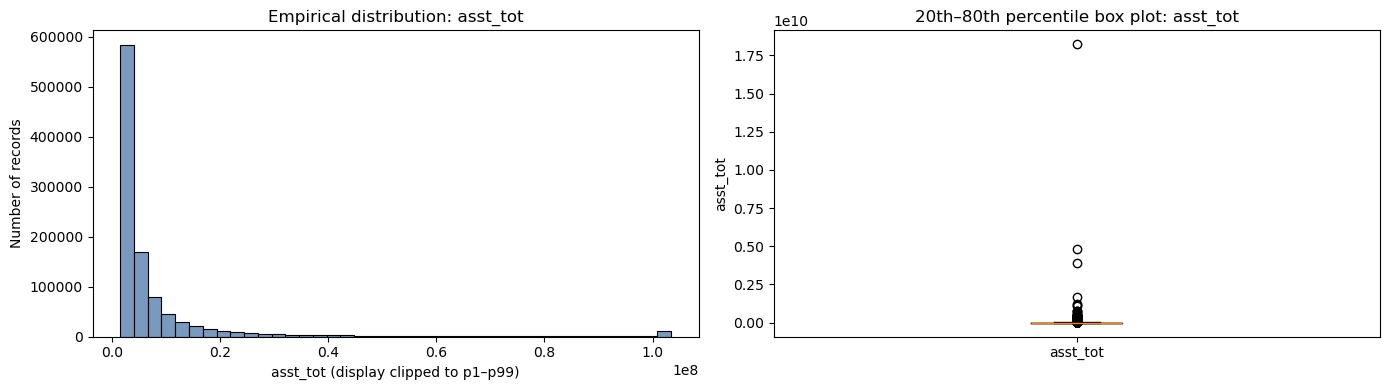

Display histogram is clipped to p1–p99; modified-Tukey outlier fences: [-7.9e+06, 1.851e+07].


**5. Additional diagnostic: median and missingness by fiscal year**

,n_observed,pct_missing,median
fs_year,,,
2007,144528,0.0,3371689.0
2008,161863,0.0,3498167.0
2009,171150,0.0,3450292.5
2010,175399,0.0,3471158.0
2011,184973,0.0,3475670.0
2012,185639,0.0,3474187.0


**1. Missing values, anomalies, and outliers**

,variable,n_missing,pct_missing,n_anomalies,n_outliers
0,eqty_tot,1,0.0,0,85083


**2. Summary statistics**

,variable,mean,mode,std,min,p10,p20,p25,median,p75,p80,p90,max
0,eqty_tot,3.585192e+06,10000.0,8.996885e+07,-805292000.0,35861.0,113619.0,167352.5,718923.0,2059212.5,2655807.0,5351272.0,3.356488e+10


**3–4. Empirical distribution and 20th–80th percentile box plot**

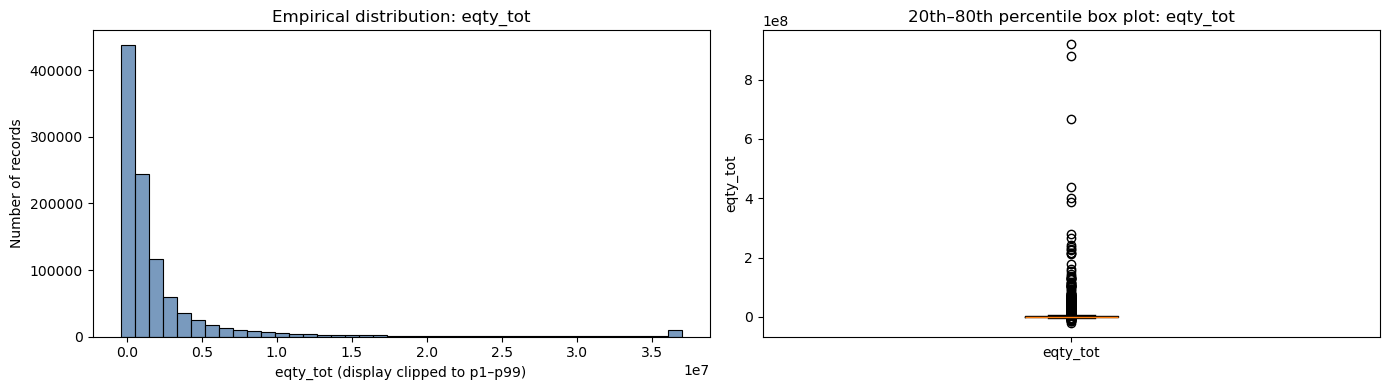

Display histogram is clipped to p1–p99; modified-Tukey outlier fences: [-3.7e+06, 6.469e+06].


**5. Additional diagnostic: median and missingness by fiscal year**

,n_observed,pct_missing,median
fs_year,,,
2007,144528,0.0,565722.5
2008,161863,0.0,748680.0
2009,171150,0.0,753944.0
2010,175399,0.0,739088.0
2011,184972,0.0,737379.5
2012,185639,0.0,770411.0


**1. Missing values, anomalies, and outliers**

,variable,n_missing,pct_missing,n_anomalies,n_outliers
0,eqty_corp_family_tot,1023552,100.0,0,0


**2. Summary statistics**

... (6 outputs left out)

,variable,n_missing,pct_missing,n_anomalies,n_outliers
0,liab_lt,294,0.03,890,140143


**2. Summary statistics**

,variable,mean,mode,std,min,p10,p20,p25,median,p75,p80,p90,max
0,liab_lt,338574.7871,0.0,4.606932e+07,-1283245.0,0.0,0.0,0.0,0.0,20820.0,47369.6,206583.0,2.707827e+10


**3–4. Empirical distribution and 20th–80th percentile box plot**

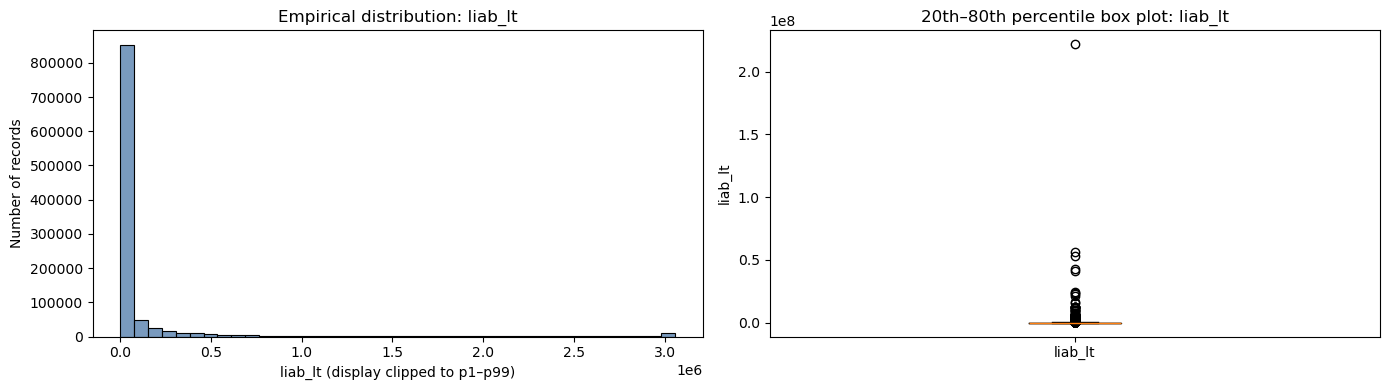

Display histogram is clipped to p1–p99; modified-Tukey outlier fences: [-7.105e+04, 1.184e+05].


**5. Additional diagnostic: median and missingness by fiscal year**

,n_observed,pct_missing,median
fs_year,,,
2007,144527,0.00,0.0
2008,161861,0.00,0.0
2009,170868,0.16,0.0
2010,175391,0.00,0.0
2011,184972,0.00,0.0
2012,185639,0.00,0.0


**1. Missing values, anomalies, and outliers**

,variable,n_missing,pct_missing,n_anomalies,n_outliers
0,liab_lt_emp,162,0.02,211,69529


**2. Summary statistics**

,variable,mean,mode,std,min,p10,p20,p25,median,p75,p80,p90,max
0,liab_lt_emp,232866.0416,0.0,5.459489e+06,-337356.0,0.0,0.0,0.0,34918.0,167193.0,219242.2,417020.3,1.734028e+09


**3–4. Empirical distribution and 20th–80th percentile box plot**

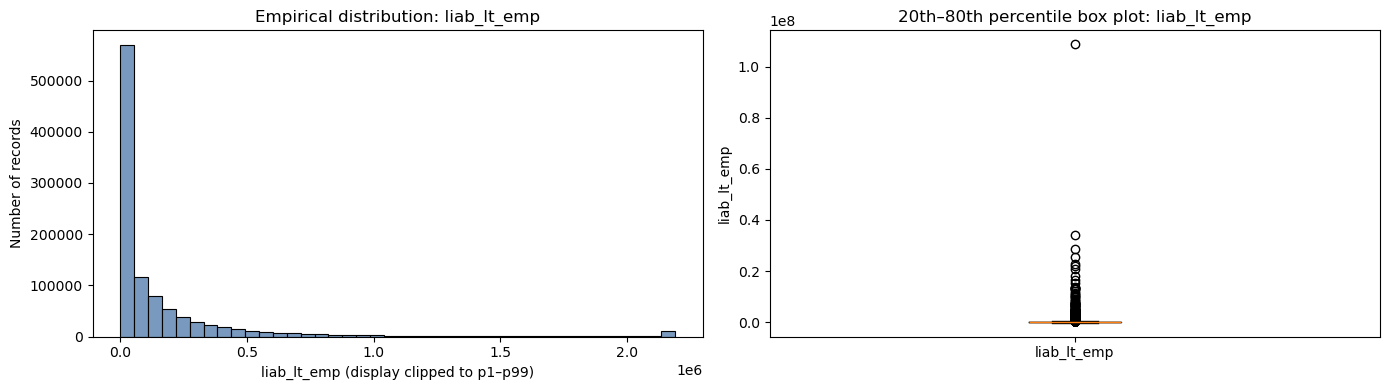

Display histogram is clipped to p1–p99; modified-Tukey outlier fences: [-3.289e+05, 5.481e+05].


**5. Additional diagnostic: median and missingness by fiscal year**

,n_observed,pct_missing,median
fs_year,,,
2007,144525,0.00,41385.0
2008,161861,0.00,35548.0
2009,170997,0.09,32890.0
2010,175396,0.00,31862.5
2011,184972,0.00,33086.0
2012,185639,0.00,35390.0


**1. Missing values, anomalies, and outliers**

,variable,n_missing,pct_missing,n_anomalies,n_outliers
0,debt_bank_st,121331,11.85,3438,73695


**2. Summary statistics**

,variable,mean,mode,std,min,p10,p20,p25,median,p75,p80,p90,max
0,debt_bank_st,1.075719e+06,0.0,5991083.63,-135046036.0,0.0,0.0,0.0,181991.0,825326.0,1092048.0,2258549.0,1.333087e+09


**3–4. Empirical distribution and 20th–80th percentile box plot**

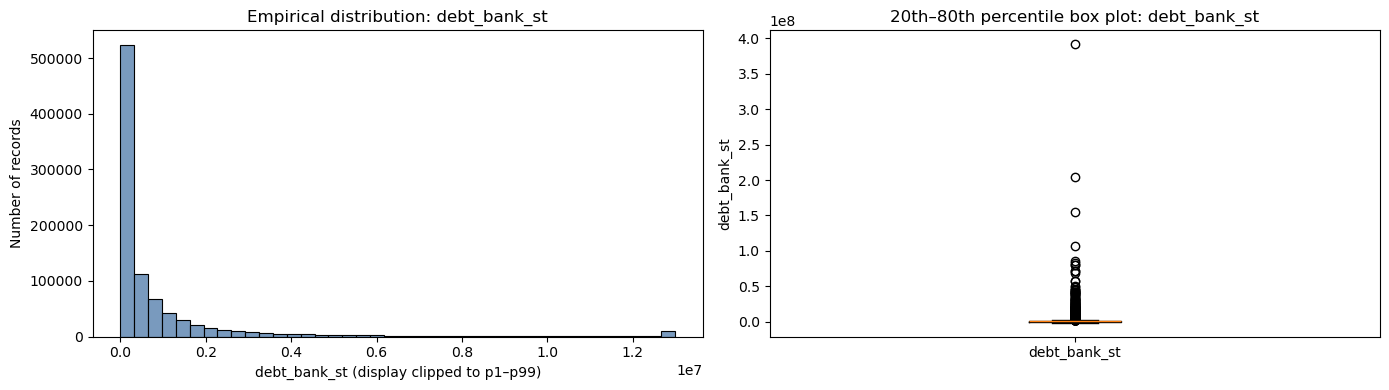

Display histogram is clipped to p1–p99; modified-Tukey outlier fences: [-1.638e+06, 2.73e+06].


**5. Additional diagnostic: median and missingness by fiscal year**

,n_observed,pct_missing,median
fs_year,,,
2007,135136,6.50,252727.5
2008,135251,16.44,224671.0
2009,141463,17.35,185072.0
2010,147880,15.69,168681.0
2011,172544,6.72,143309.5
2012,169947,8.45,151625.0


**1. Missing values, anomalies, and outliers**

,variable,n_missing,pct_missing,n_anomalies,n_outliers
0,debt_bank_lt,90971,8.89,8839,77480


**2. Summary statistics**

,variable,mean,mode,std,min,p10,p20,p25,median,p75,p80,p90,max
0,debt_bank_lt,1.133471e+06,0.0,1.337126e+07,-2301536.0,0.0,0.0,0.0,25784.0,728984.0,1010000.0,2127006.0,3.199651e+09


**3–4. Empirical distribution and 20th–80th percentile box plot**

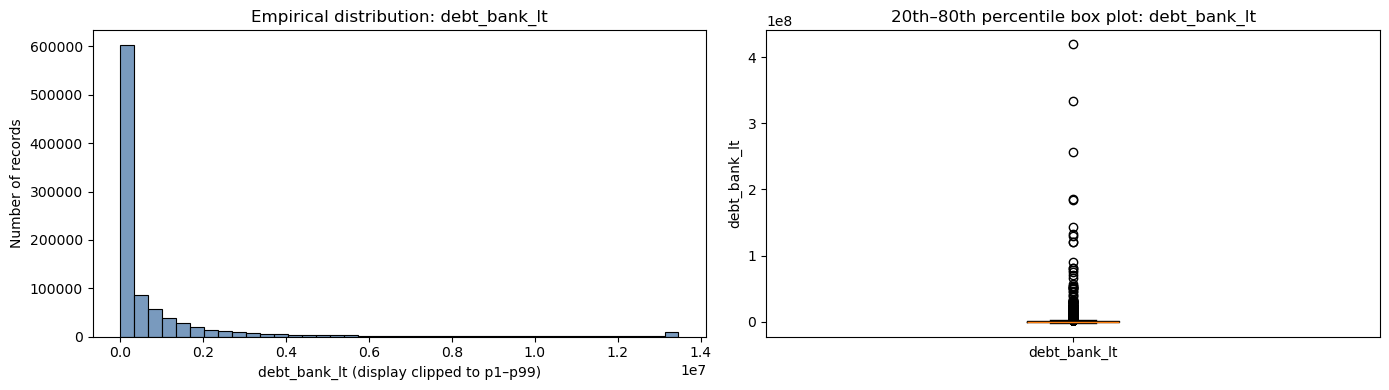

Display histogram is clipped to p1–p99; modified-Tukey outlier fences: [-1.515e+06, 2.525e+06].


**5. Additional diagnostic: median and missingness by fiscal year**

,n_observed,pct_missing,median
fs_year,,,
2007,134890,6.67,0.0
2008,144081,10.99,0.0
2009,151216,11.65,21063.0
2010,156622,10.71,40000.0
2011,172742,6.61,46302.0
2012,173030,6.79,44891.5


**1. Missing values, anomalies, and outliers**

,variable,n_missing,pct_missing,n_anomalies,n_outliers
0,debt_fin_st,122772,11.99,3191,114308


**2. Summary statistics**

,variable,mean,mode,std,min,p10,p20,p25,median,p75,p80,p90,max
0,debt_fin_st,166235.0525,0.0,9.253849e+06,-14586018.0,0.0,0.0,0.0,0.0,0.0,0.0,6791.0,3.713192e+09


**3–4. Empirical distribution and 20th–80th percentile box plot**

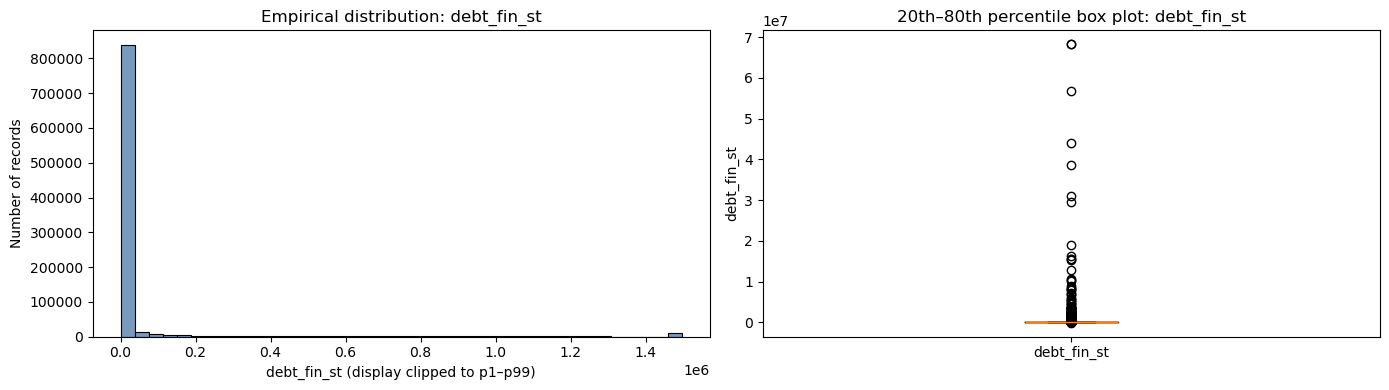

Display histogram is clipped to p1–p99; modified-Tukey outlier fences: [0, 0].


**5. Additional diagnostic: median and missingness by fiscal year**

,n_observed,pct_missing,median
fs_year,,,
2007,135133,6.50,0.0
2008,135231,16.45,0.0
2009,141314,17.43,0.0
2010,146611,16.41,0.0
2011,172544,6.72,0.0
2012,169947,8.45,0.0


**1. Missing values, anomalies, and outliers**

,variable,n_missing,pct_missing,n_anomalies,n_outliers
0,debt_fin_lt,92068,8.99,8815,79604


**2. Summary statistics**

,variable,mean,mode,std,min,p10,p20,p25,median,p75,p80,p90,max
0,debt_fin_lt,117477.4763,0.0,4.398384e+06,-5449856.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.229168e+09


**3–4. Empirical distribution and 20th–80th percentile box plot**

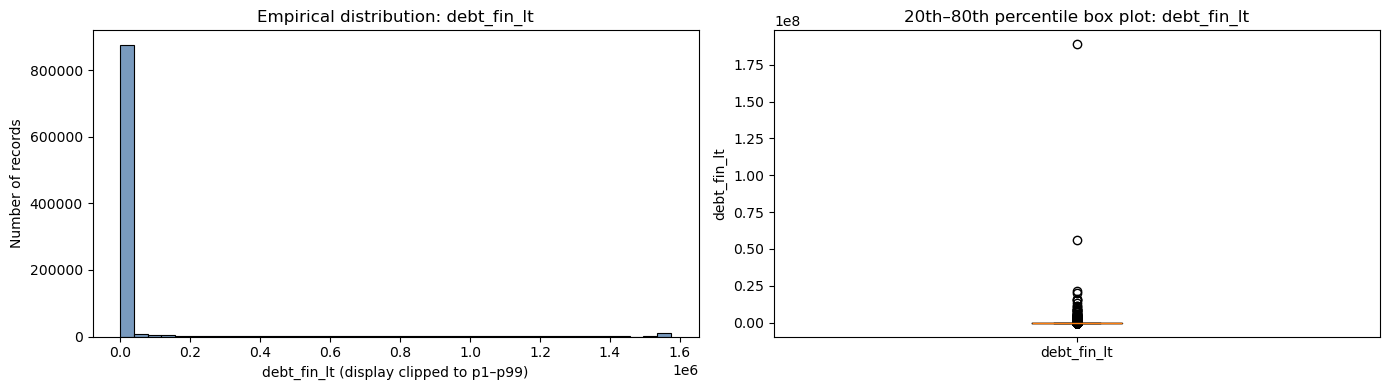

Display histogram is clipped to p1–p99; modified-Tukey outlier fences: [0, 0].


**5. Additional diagnostic: median and missingness by fiscal year**

,n_observed,pct_missing,median
fs_year,,,
2007,134889,6.67,0.0
2008,144078,10.99,0.0
2009,151115,11.71,0.0
2010,155630,11.27,0.0
2011,172742,6.61,0.0
2012,173030,6.79,0.0


**1. Missing values, anomalies, and outliers**

,variable,n_missing,pct_missing,n_anomalies,n_outliers
0,AP_st,120635,11.79,3956,63861


**2. Summary statistics**

,variable,mean,mode,std,min,p10,p20,p25,median,p75,p80,p90,max
0,AP_st,1.884860e+06,0.0,1.999876e+07,-679472294.0,8161.6,47421.2,89107.0,504871.0,1360665.0,1700981.4,3166447.6,4.114046e+09


**3–4. Empirical distribution and 20th–80th percentile box plot**

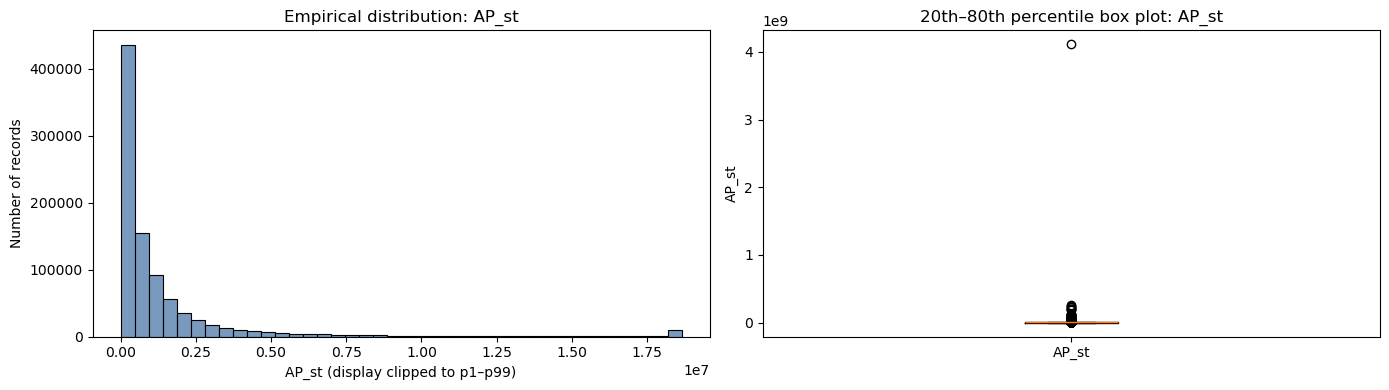

Display histogram is clipped to p1–p99; modified-Tukey outlier fences: [-2.433e+06, 4.181e+06].


**5. Additional diagnostic: median and missingness by fiscal year**

,n_observed,pct_missing,median
fs_year,,,
2007,135137,6.50,615201.0
2008,135259,16.44,565520.0
2009,141533,17.30,508432.0
2010,148498,15.34,496840.5
2011,172544,6.72,446331.0
2012,169946,8.45,441100.0


**1. Missing values, anomalies, and outliers**

,variable,n_missing,pct_missing,n_anomalies,n_outliers
0,AP_lt,92244,9.01,8877,21054


**2. Summary statistics**

,variable,mean,mode,std,min,p10,p20,p25,median,p75,p80,p90,max
0,AP_lt,22936.5602,0.0,1.297701e+06,-587978.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,733288000.0


**3–4. Empirical distribution and 20th–80th percentile box plot**

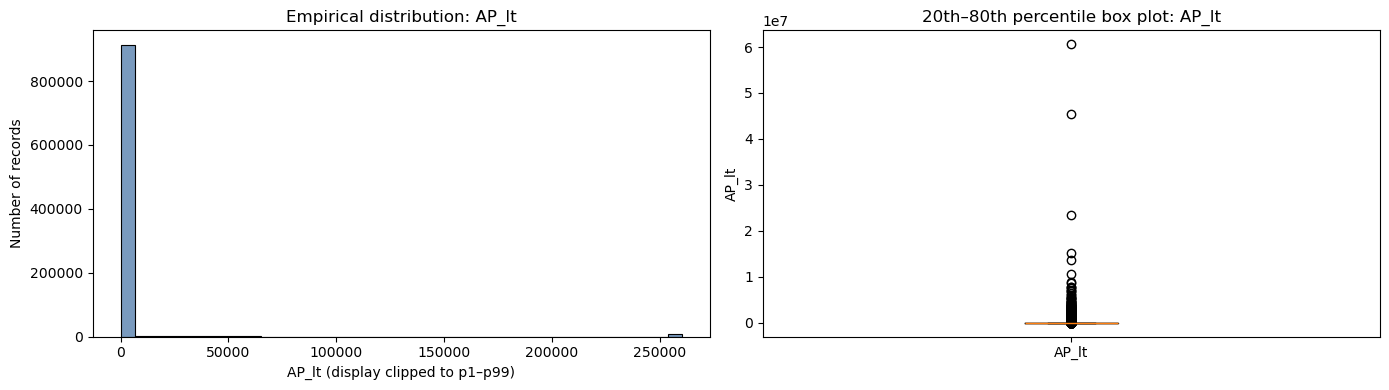

Display histogram is clipped to p1–p99; modified-Tukey outlier fences: [0, 0].


**5. Additional diagnostic: median and missingness by fiscal year**

,n_observed,pct_missing,median
fs_year,,,
2007,134888,6.67,0.0
2008,144069,10.99,0.0
2009,151088,11.72,0.0
2010,155494,11.35,0.0
2011,172740,6.61,0.0
2012,173029,6.79,0.0


**1. Missing values, anomalies, and outliers**

,variable,n_missing,pct_missing,n_anomalies,n_outliers
0,debt_st,5,0.0,3122,78517


**2. Summary statistics**

,variable,mean,mode,std,min,p10,p20,p25,median,p75,p80,p90,max
0,debt_st,4.824535e+06,0.0,5.557351e+07,-77594263.0,179118.6,511799.2,689199.0,1533884.0,3142571.0,3871717.6,7143062.4,1.487525e+10


**3–4. Empirical distribution and 20th–80th percentile box plot**

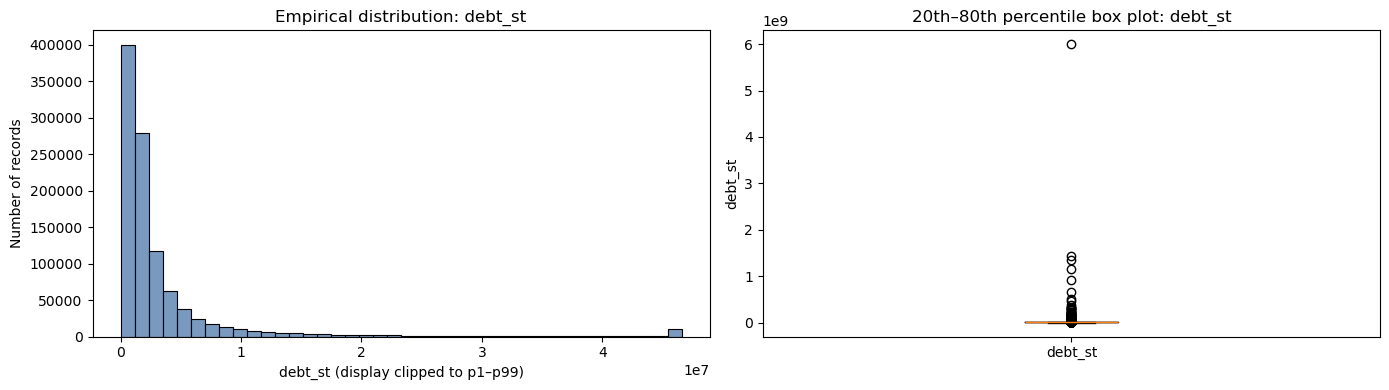

Display histogram is clipped to p1–p99; modified-Tukey outlier fences: [-4.528e+06, 8.912e+06].


**5. Additional diagnostic: median and missingness by fiscal year**

,n_observed,pct_missing,median
fs_year,,,
2007,144528,0.0,1717493.5
2008,161862,0.0,1563469.5
2009,171147,0.0,1500669.0
2010,175399,0.0,1501862.0
2011,184972,0.0,1503169.0
2012,185639,0.0,1456920.0


**1. Missing values, anomalies, and outliers**

,variable,n_missing,pct_missing,n_anomalies,n_outliers
0,debt_lt,155,0.02,8946,73083


**2. Summary statistics**

,variable,mean,mode,std,min,p10,p20,p25,median,p75,p80,p90,max
0,debt_lt,1982038.824,0.0,26539713.58,-9602000.0,0.0,0.0,0.0,365385.0,1424715.0,1800416.8,3395153.8,8.838206e+09


**3–4. Empirical distribution and 20th–80th percentile box plot**

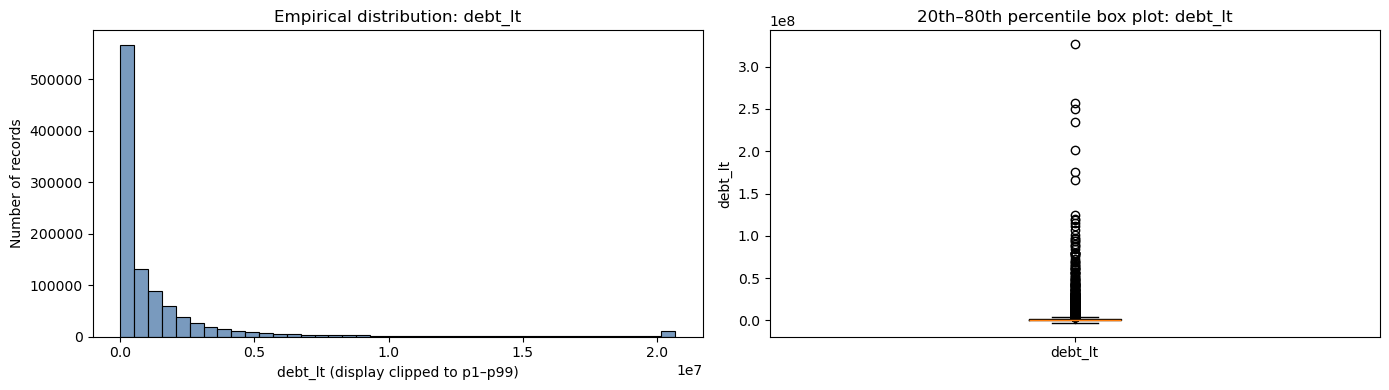

Display histogram is clipped to p1–p99; modified-Tukey outlier fences: [-2.701e+06, 4.501e+06].


**5. Additional diagnostic: median and missingness by fiscal year**

,n_observed,pct_missing,median
fs_year,,,
2007,144526,0.00,290829.0
2008,161861,0.00,342523.0
2009,171006,0.08,370002.0
2010,175395,0.00,396459.0
2011,184970,0.00,391216.0
2012,185639,0.00,390000.0


**1. Missing values, anomalies, and outliers**

,variable,n_missing,pct_missing,n_anomalies,n_outliers
0,rev_operating,174,0.02,3270,79972


**2. Summary statistics**

,variable,mean,mode,std,min,p10,p20,p25,median,p75,p80,p90,max
0,rev_operating,8.645592e+06,0.0,1.404518e+08,-111729936.0,83334.0,272177.4,433067.25,1983749.0,4953758.5,6252045.8,12201318.5,4.320688e+10


**3–4. Empirical distribution and 20th–80th percentile box plot**

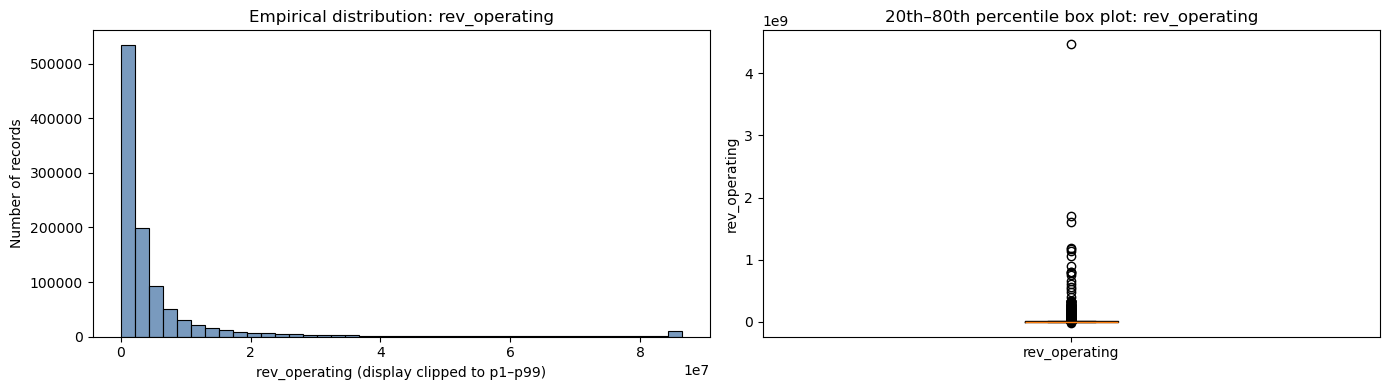

Display histogram is clipped to p1–p99; modified-Tukey outlier fences: [-8.698e+06, 1.522e+07].


**5. Additional diagnostic: median and missingness by fiscal year**

,n_observed,pct_missing,median
fs_year,,,
2007,144514,0.01,2563564.5
2008,161847,0.01,2250185.0
2009,171075,0.04,1850218.0
2010,175333,0.04,1832095.0
2011,184970,0.00,1835148.5
2012,185639,0.00,1728772.0


**1. Missing values, anomalies, and outliers**

,variable,n_missing,pct_missing,n_anomalies,n_outliers
0,COGS,24,0.0,7655,79998


**2. Summary statistics**

,variable,mean,mode,std,min,p10,p20,p25,median,p75,p80,p90,max
0,COGS,8.355932e+06,0.0,1.391105e+08,-50492693.0,73688.0,230777.0,381267.25,1886857.0,4752647.25,6005964.0,11756297.6,4.326022e+10


**3–4. Empirical distribution and 20th–80th percentile box plot**

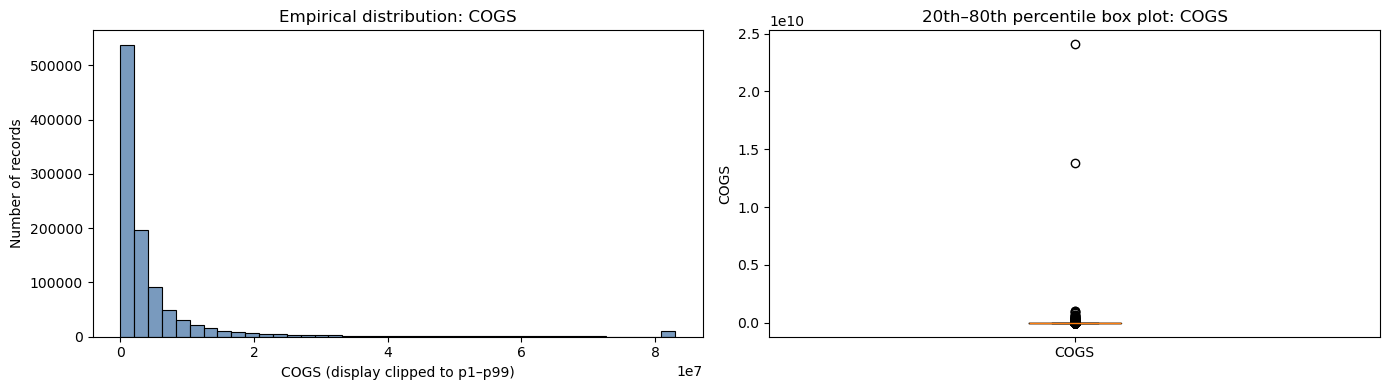

Display histogram is clipped to p1–p99; modified-Tukey outlier fences: [-8.432e+06, 1.467e+07].


**5. Additional diagnostic: median and missingness by fiscal year**

,n_observed,pct_missing,median
fs_year,,,
2007,144518,0.01,2401837.0
2008,161856,0.00,2125909.5
2009,171147,0.00,1778595.0
2010,175397,0.00,1752753.0
2011,184971,0.00,1748270.0
2012,185639,0.00,1660117.0


**1. Missing values, anomalies, and outliers**

,variable,n_missing,pct_missing,n_anomalies,n_outliers
0,prof_operations,21,0.0,44,116160


**2. Summary statistics**

,variable,mean,mode,std,min,p10,p20,p25,median,p75,p80,p90,max
0,prof_operations,288391.546,0.0,1.213742e+07,-5.435912e+09,-99709.0,-10012.0,3849.0,82598.0,235408.5,305560.0,621755.0,3.317533e+09


**3–4. Empirical distribution and 20th–80th percentile box plot**

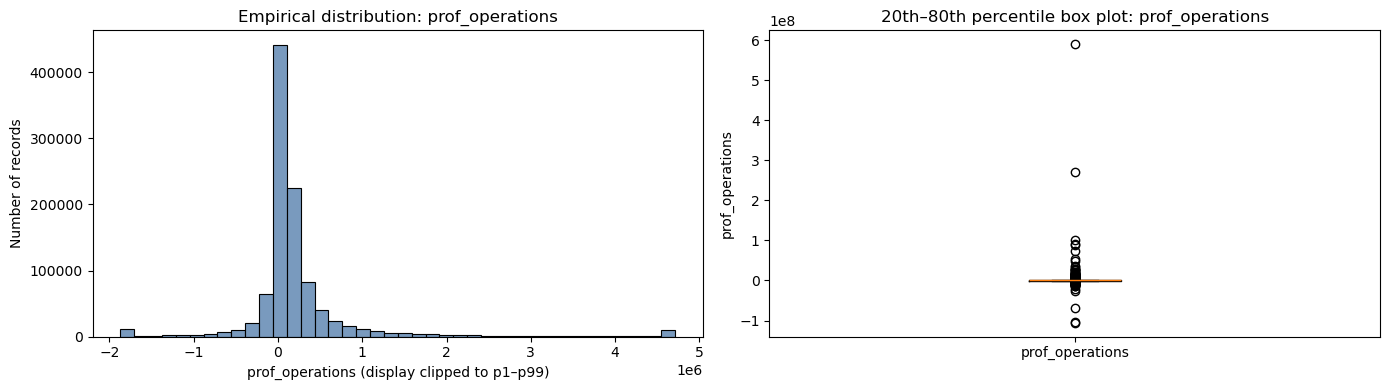

Display histogram is clipped to p1–p99; modified-Tukey outlier fences: [-4.834e+05, 7.789e+05].


**5. Additional diagnostic: median and missingness by fiscal year**

,n_observed,pct_missing,median
fs_year,,,
2007,144518,0.01,126577.0
2008,161856,0.00,104504.5
2009,171148,0.00,71735.5
2010,175399,0.00,72808.0
2011,184971,0.00,75814.0
2012,185639,0.00,63445.0


**1. Missing values, anomalies, and outliers**

,variable,n_missing,pct_missing,n_anomalies,n_outliers
0,goodwill,21,0.0,107638,78931


**2. Summary statistics**

,variable,mean,mode,std,min,p10,p20,p25,median,p75,p80,p90,max
0,goodwill,1.612102e+06,0.0,2.193186e+07,-5.435823e+09,-1403.0,63660.0,101693.0,420702.0,1074216.5,1350133.0,2553372.0,5.632980e+09


**3–4. Empirical distribution and 20th–80th percentile box plot**

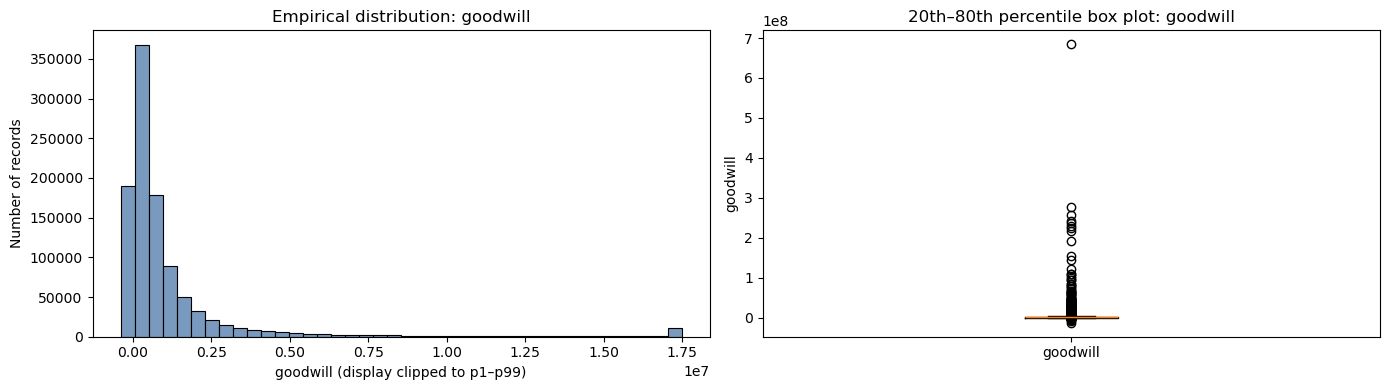

Display histogram is clipped to p1–p99; modified-Tukey outlier fences: [-1.866e+06, 3.28e+06].


**5. Additional diagnostic: median and missingness by fiscal year**

,n_observed,pct_missing,median
fs_year,,,
2007,144518,0.01,514342.5
2008,161856,0.00,456496.0
2009,171148,0.00,393022.5
2010,175399,0.00,394876.0
2011,184971,0.00,402711.0
2012,185639,0.00,389775.0


**1. Missing values, anomalies, and outliers**

,variable,n_missing,pct_missing,n_anomalies,n_outliers
0,inc_financing,26,0.0,0,98686


**2. Summary statistics**

,variable,mean,mode,std,min,p10,p20,p25,median,p75,p80,p90,max
0,inc_financing,-65460.6232,0.0,3.073927e+06,-891950000.0,-203869.5,-108557.0,-86686.0,-32164.0,-2586.0,-205.0,8404.0,1.028015e+09


**3–4. Empirical distribution and 20th–80th percentile box plot**

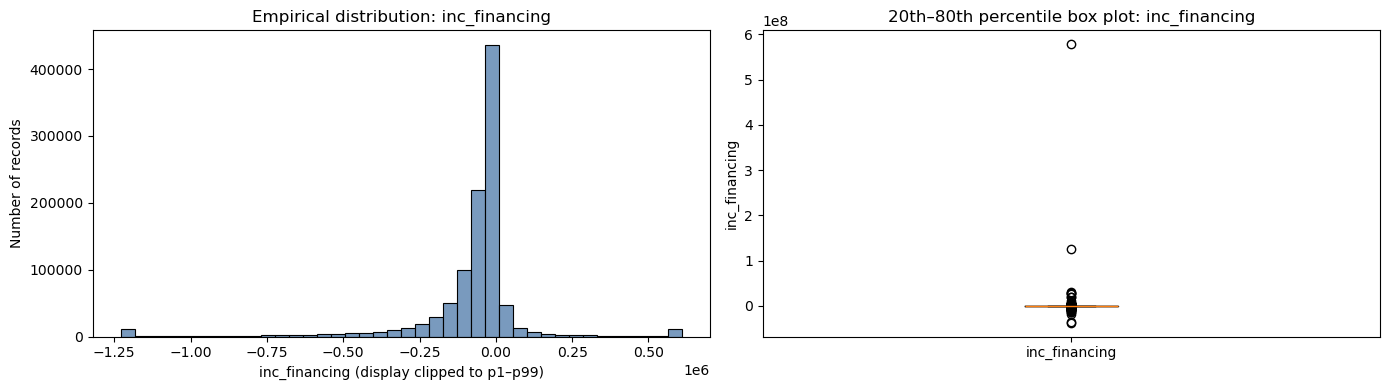

Display histogram is clipped to p1–p99; modified-Tukey outlier fences: [-2.711e+05, 1.623e+05].


**5. Additional diagnostic: median and missingness by fiscal year**

,n_observed,pct_missing,median
fs_year,,,
2007,144518,0.01,-45387.5
2008,161856,0.00,-46086.5
2009,171145,0.00,-31732.0
2010,175396,0.00,-24267.0
2011,184972,0.00,-27683.0
2012,185639,0.00,-28578.0


**1. Missing values, anomalies, and outliers**

,variable,n_missing,pct_missing,n_anomalies,n_outliers
0,exp_financing,367,0.04,720,76732


**2. Summary statistics**

,variable,mean,mode,std,min,p10,p20,p25,median,p75,p80,p90,max
0,exp_financing,162044.1475,0.0,5.367188e+06,-5307809.0,438.0,4650.0,8660.0,38682.0,97721.0,122772.2,233240.2,4.389405e+09


**3–4. Empirical distribution and 20th–80th percentile box plot**

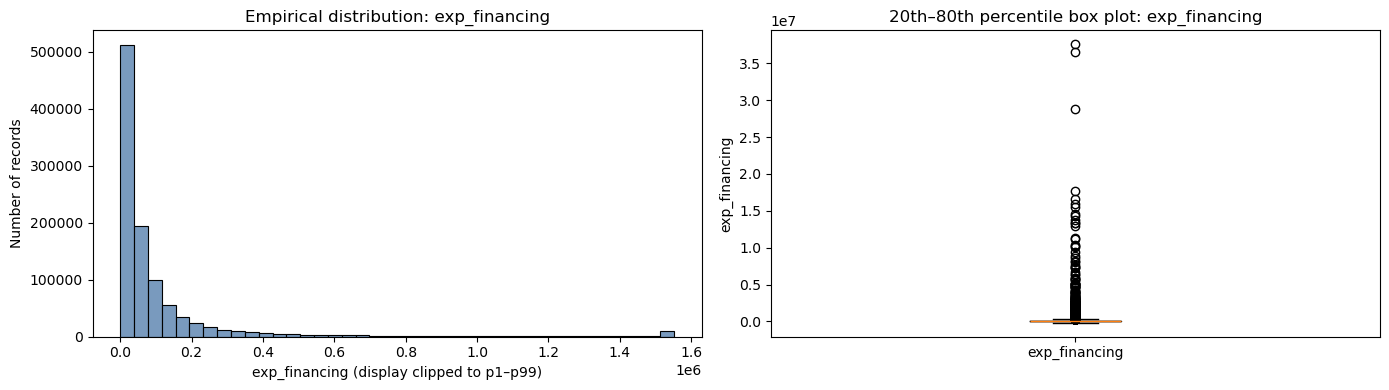

Display histogram is clipped to p1–p99; modified-Tukey outlier fences: [-1.725e+05, 3e+05].


**5. Additional diagnostic: median and missingness by fiscal year**

,n_observed,pct_missing,median
fs_year,,,
2007,144466,0.04,53946.5
2008,161738,0.08,54896.0
2009,171053,0.06,37959.0
2010,175320,0.05,29220.0
2011,184969,0.00,33140.0
2012,185639,0.00,34440.0


**1. Missing values, anomalies, and outliers**

,variable,n_missing,pct_missing,n_anomalies,n_outliers
0,prof_financing,656,0.06,43236,43236


**2. Summary statistics**

,variable,mean,mode,std,min,p10,p20,p25,median,p75,p80,p90,max
0,prof_financing,-38798.0921,0.0,4.333345e+06,-1.851942e+09,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.105765e+09


**3–4. Empirical distribution and 20th–80th percentile box plot**

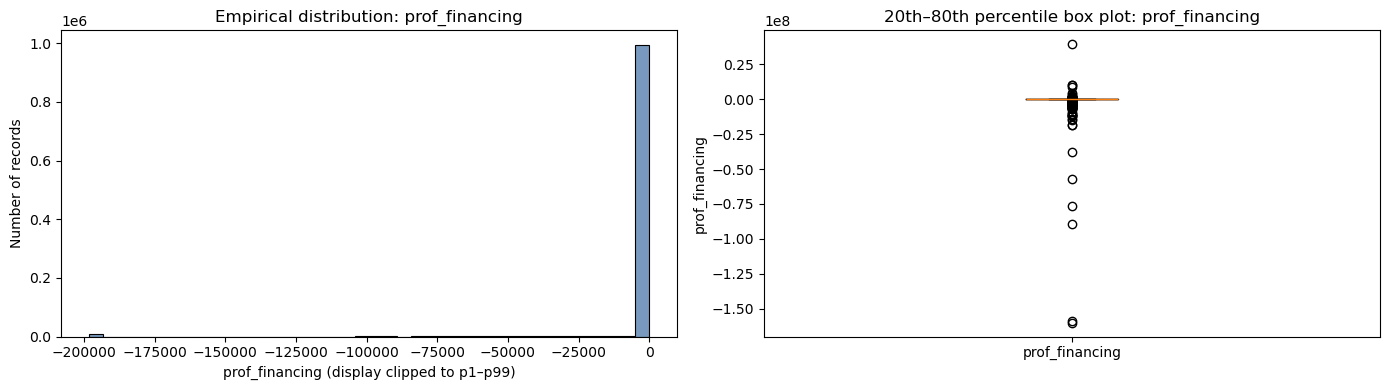

Display histogram is clipped to p1–p99; modified-Tukey outlier fences: [0, 0].


**5. Additional diagnostic: median and missingness by fiscal year**

,n_observed,pct_missing,median
fs_year,,,
2007,144509,0.01,0.0
2008,161778,0.05,0.0
2009,170680,0.27,0.0
2010,175320,0.05,0.0
2011,184970,0.00,0.0
2012,185639,0.00,0.0


**1. Missing values, anomalies, and outliers**

,variable,n_missing,pct_missing,n_anomalies,n_outliers
0,inc_extraord,305,0.03,0,227603


**2. Summary statistics**

,variable,mean,mode,std,min,p10,p20,p25,median,p75,p80,p90,max
0,inc_extraord,27156.7436,0.0,3322200.069,-972441470.0,-15673.0,-1935.0,-399.0,0.0,3855.0,8911.0,39999.0,1.849907e+09


**3–4. Empirical distribution and 20th–80th percentile box plot**

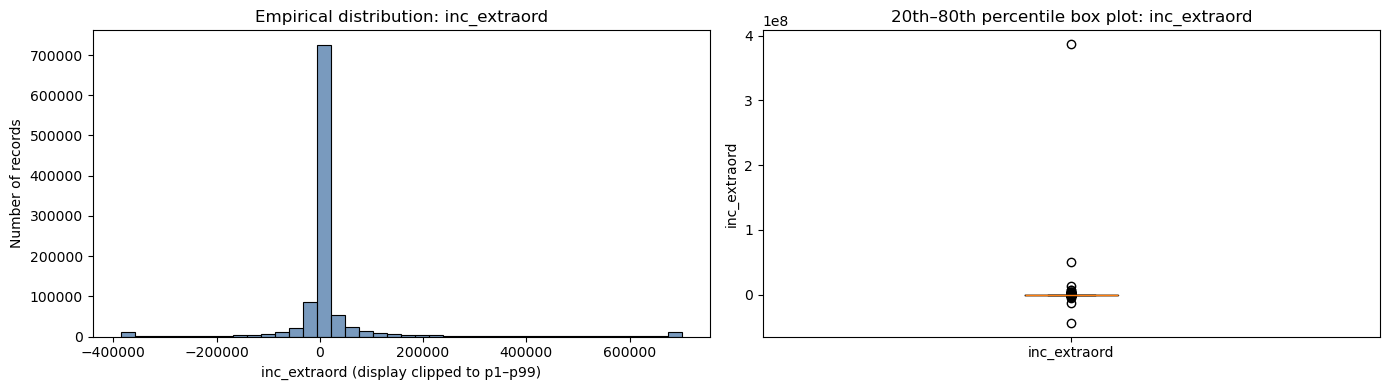

Display histogram is clipped to p1–p99; modified-Tukey outlier fences: [-1.82e+04, 2.518e+04].


**5. Additional diagnostic: median and missingness by fiscal year**

,n_observed,pct_missing,median
fs_year,,,
2007,144513,0.01,0.0
2008,161782,0.05,0.0
2009,171015,0.08,0.0
2010,175328,0.04,0.0
2011,184970,0.00,0.0
2012,185639,0.00,1.0


**1. Missing values, anomalies, and outliers**

,variable,n_missing,pct_missing,n_anomalies,n_outliers
0,taxes,32,0.0,0,138624


**2. Summary statistics**

,variable,mean,mode,std,min,p10,p20,p25,median,p75,p80,p90,max
0,taxes,221871.2687,0.0,1.092509e+07,-1.953236e+09,-148026.2,-29899.2,-10759.0,40584.0,168097.25,233889.6,542028.0,3.142607e+09


**3–4. Empirical distribution and 20th–80th percentile box plot**

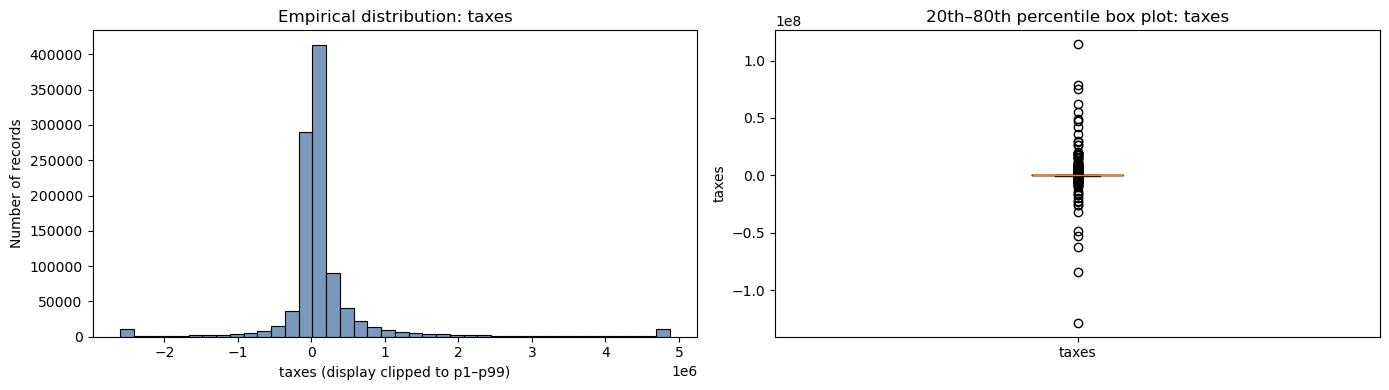

Display histogram is clipped to p1–p99; modified-Tukey outlier fences: [-4.256e+05, 6.296e+05].


**5. Additional diagnostic: median and missingness by fiscal year**

,n_observed,pct_missing,median
fs_year,,,
2007,144518,0.01,67030.5
2008,161844,0.01,45382.5
2009,171149,0.00,32484.0
2010,175398,0.00,39027.0
2011,184972,0.00,38851.0
2012,185639,0.00,31062.0


**1. Missing values, anomalies, and outliers**

,variable,n_missing,pct_missing,n_anomalies,n_outliers
0,profit,20,0.0,0,156425


**2. Summary statistics**

,variable,mean,mode,std,min,p10,p20,p25,median,p75,p80,p90,max
0,profit,82349.3954,0.0,8.867946e+06,-1.914960e+09,-158872.7,-41906.8,-21650.0,10888.0,85288.5,126597.0,328672.7,2.314332e+09


**3–4. Empirical distribution and 20th–80th percentile box plot**

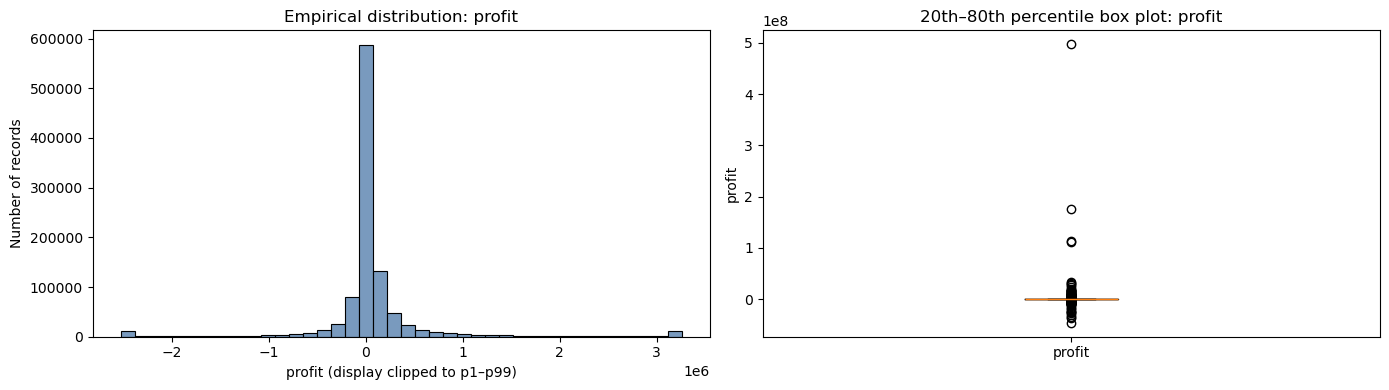

Display histogram is clipped to p1–p99; modified-Tukey outlier fences: [-2.947e+05, 3.794e+05].


**5. Additional diagnostic: median and missingness by fiscal year**

,n_observed,pct_missing,median
fs_year,,,
2007,144518,0.01,18697.0
2008,161856,0.00,12545.5
2009,171149,0.00,7744.0
2010,175398,0.00,10735.5
2011,184972,0.00,10279.5
2012,185639,0.00,8240.0


**1. Missing values, anomalies, and outliers**

,variable,n_missing,pct_missing,n_anomalies,n_outliers
0,days_rec,740211,72.32,0,6792


**2. Summary statistics**

,variable,mean,mode,std,min,p10,p20,p25,median,p75,p80,p90,max
0,days_rec,84.8868,0.0,167.3107,-499.41,-76.94,-20.42,-3.72,66.42,158.49,186.36,276.49,2295.84


**3–4. Empirical distribution and 20th–80th percentile box plot**

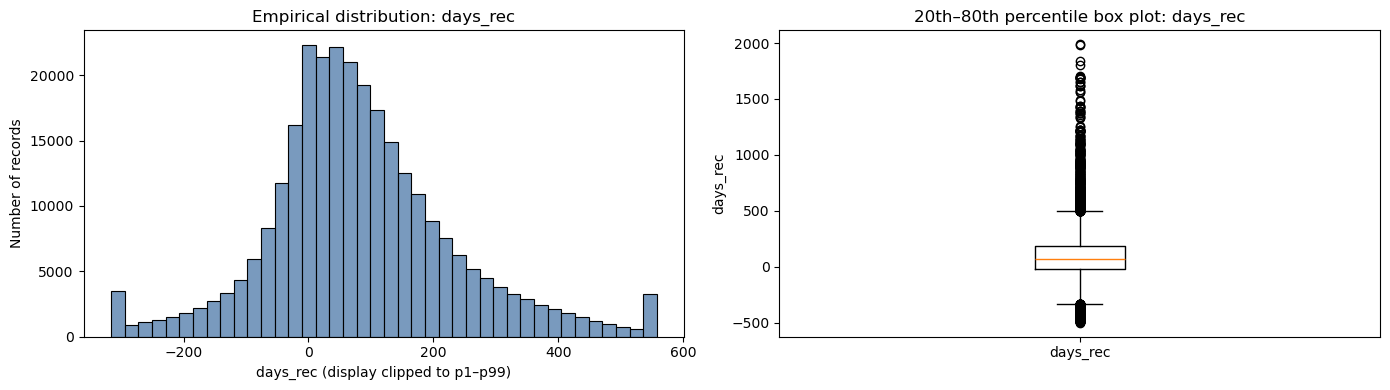

Display histogram is clipped to p1–p99; modified-Tukey outlier fences: [-330.6, 496.5].


**5. Additional diagnostic: median and missingness by fiscal year**

,n_observed,pct_missing,median
fs_year,,,
2007,47825,66.91,70.770
2008,47500,70.65,70.555
2009,45805,73.24,69.540
2010,45045,74.32,67.650
2011,48873,73.58,59.400
2012,48293,73.99,59.970


**1. Missing values, anomalies, and outliers**

,variable,n_missing,pct_missing,n_anomalies,n_outliers
0,ebitda,81,0.01,44,97358


**2. Summary statistics**

,variable,mean,mode,std,min,p10,p20,p25,median,p75,p80,p90,max
0,ebitda,607097.0592,0.0,1.507074e+07,-5.435868e+09,-31508.0,17080.0,40040.0,150403.0,381344.0,484564.0,957726.0,4.227442e+09


**3–4. Empirical distribution and 20th–80th percentile box plot**

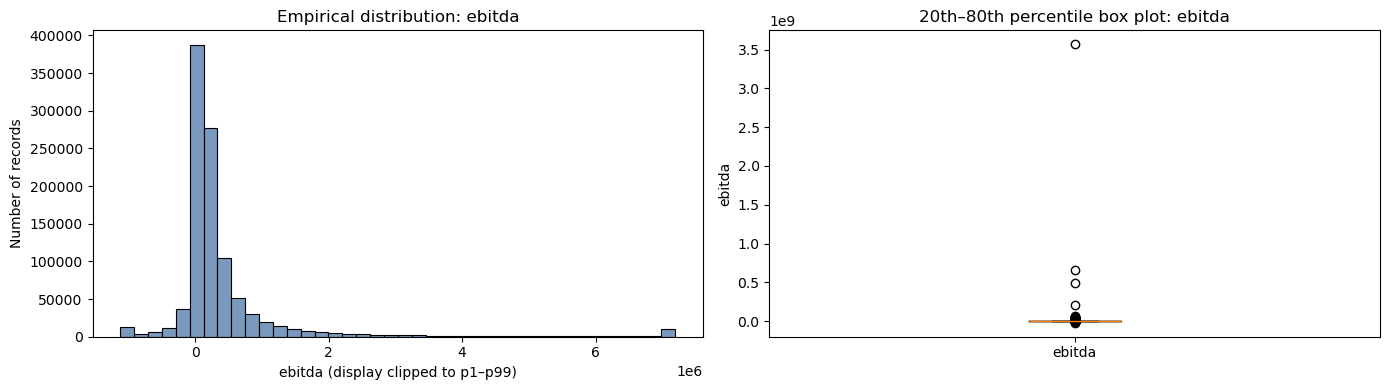

Display histogram is clipped to p1–p99; modified-Tukey outlier fences: [-6.841e+05, 1.186e+06].


**5. Additional diagnostic: median and missingness by fiscal year**

,n_observed,pct_missing,median
fs_year,,,
2007,144500,0.02,200672.0
2008,161855,0.00,171824.0
2009,171109,0.02,136727.0
2010,175397,0.00,138154.0
2011,184971,0.00,142385.0
2012,185639,0.00,129462.0


**1. Missing values, anomalies, and outliers**

,variable,n_missing,pct_missing,n_anomalies,n_outliers
0,roa,27,0.0,0,77386


**2. Summary statistics**

,variable,mean,mode,std,min,p10,p20,p25,median,p75,p80,p90,max
0,roa,2.9146,0.0,10.2338,-963.9,-2.25,-0.27,0.11,2.39,5.2,6.17,10.02,907.56


**3–4. Empirical distribution and 20th–80th percentile box plot**

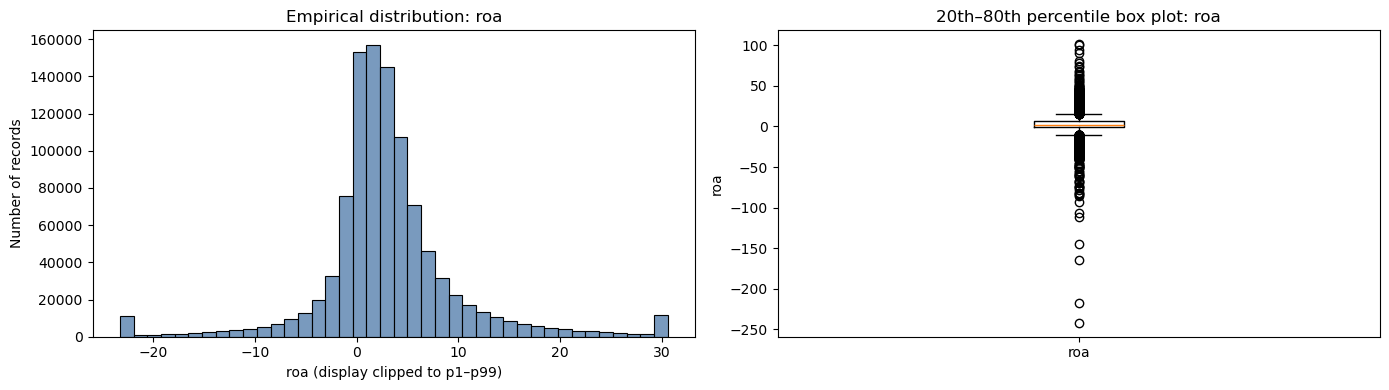

Display histogram is clipped to p1–p99; modified-Tukey outlier fences: [-9.93, 15.83].


**5. Additional diagnostic: median and missingness by fiscal year**

,n_observed,pct_missing,median
fs_year,,,
2007,144518,0.01,3.70
2008,161850,0.01,3.01
2009,171148,0.00,2.08
2010,175399,0.00,2.08
2011,184971,0.00,2.20
2012,185639,0.00,1.84


**1. Missing values, anomalies, and outliers**

,variable,n_missing,pct_missing,n_anomalies,n_outliers
0,roe,72937,7.13,0,105115


**2. Summary statistics**

,variable,mean,mode,std,min,p10,p20,p25,median,p75,p80,p90,max
0,roe,4.0606,0.0,28.8701,-150.0,-18.3,-3.94,-1.5,2.56,13.15,17.35,32.2,149.99


**3–4. Empirical distribution and 20th–80th percentile box plot**

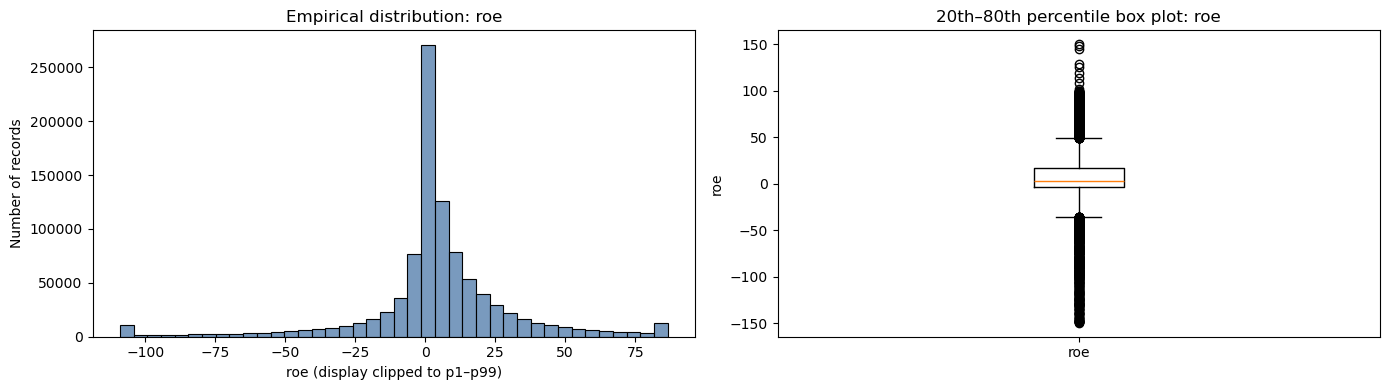

Display histogram is clipped to p1–p99; modified-Tukey outlier fences: [-35.88, 49.29].


**5. Additional diagnostic: median and missingness by fiscal year**

,n_observed,pct_missing,median
fs_year,,,
2007,135072,6.54,5.15
2008,150521,7.01,2.74
2009,158490,7.40,1.87
2010,163334,6.88,2.42
2011,172069,6.98,2.30
2012,171129,7.82,2.00


**1. Missing values, anomalies, and outliers**

,variable,n_missing,pct_missing,n_anomalies,n_outliers
0,wc_net,6,0.0,0,97756


**2. Summary statistics**

,variable,mean,mode,std,min,p10,p20,p25,median,p75,p80,p90,max
0,wc_net,1.133337e+06,1530551.0,2.009072e+07,-4.130538e+09,-879588.5,-244489.0,-100990.0,366913.0,1374780.25,1739700.0,3352536.5,3.768695e+09


**3–4. Empirical distribution and 20th–80th percentile box plot**

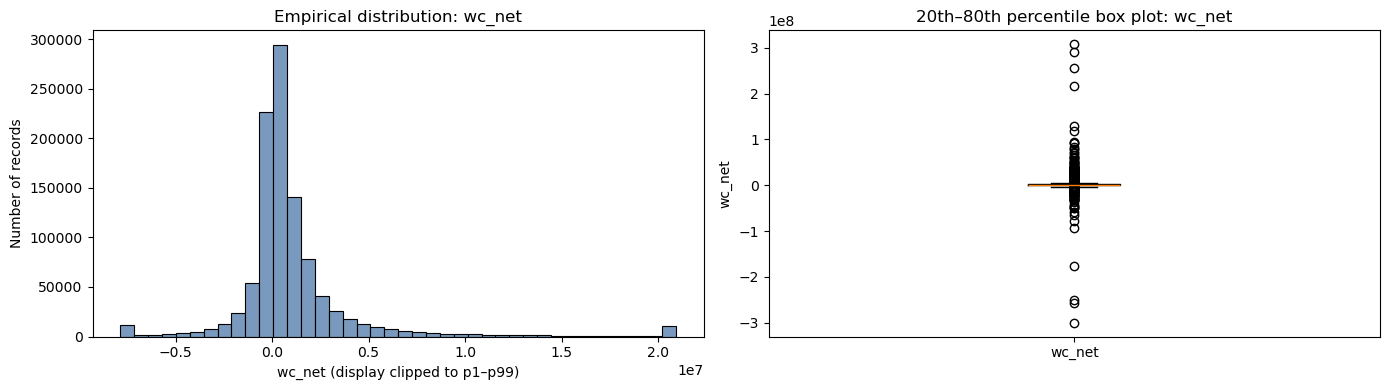

Display histogram is clipped to p1–p99; modified-Tukey outlier fences: [-3.221e+06, 4.716e+06].


**5. Additional diagnostic: median and missingness by fiscal year**

,n_observed,pct_missing,median
fs_year,,,
2007,144528,0.0,375933.5
2008,161861,0.0,352308.0
2009,171147,0.0,359034.0
2010,175399,0.0,374155.0
2011,184972,0.0,361173.5
2012,185639,0.0,378905.0


**1. Missing values, anomalies, and outliers**

,variable,n_missing,pct_missing,n_anomalies,n_outliers
0,margin_fin,40758,3.98,0,100856


**2. Summary statistics**

,variable,mean,mode,std,min,p10,p20,p25,median,p75,p80,p90,max
0,margin_fin,-1.381130e+06,1189676.0,6.858357e+07,-3.204300e+10,-3024685.9,-1491428.6,-1118977.75,-101960.0,347032.25,557561.4,1427584.2,1.830129e+09


**3–4. Empirical distribution and 20th–80th percentile box plot**

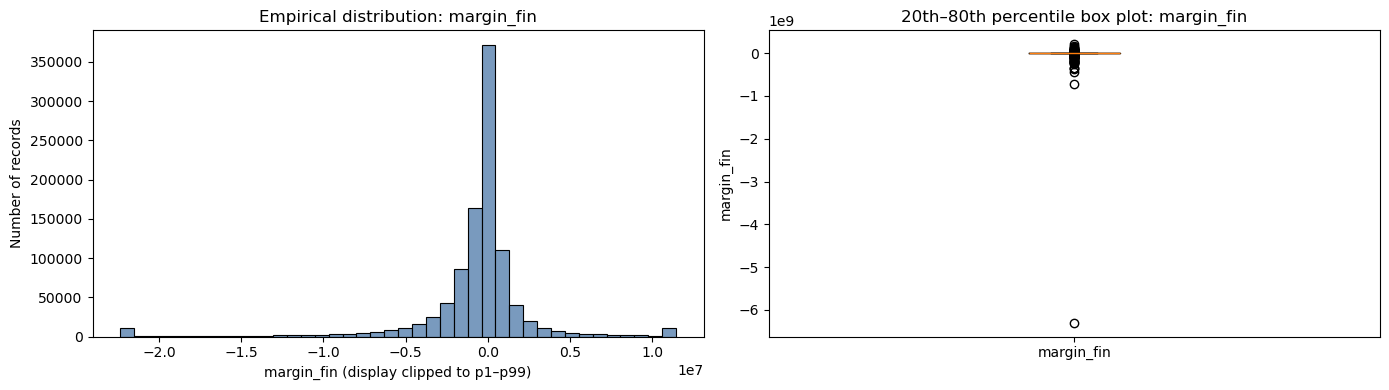

Display histogram is clipped to p1–p99; modified-Tukey outlier fences: [-4.565e+06, 3.631e+06].


**5. Additional diagnostic: median and missingness by fiscal year**

,n_observed,pct_missing,median
fs_year,,,
2007,139062,3.78,-67722.5
2008,155471,3.95,-99248.0
2009,164112,4.11,-105626.5
2010,168678,3.83,-109727.5
2011,177785,3.89,-112943.0
2012,177686,4.28,-112241.5


**1. Missing values, anomalies, and outliers**

,variable,n_missing,pct_missing,n_anomalies,n_outliers
0,cf_operations,88,0.01,0,114132


**2. Summary statistics**

,variable,mean,mode,std,min,p10,p20,p25,median,p75,p80,p90,max
0,cf_operations,404148.8678,0.0,1.202904e+07,-1.914280e+09,-67670.4,-5585.0,4902.0,76045.0,239390.0,313440.8,660716.5,3.377050e+09


**3–4. Empirical distribution and 20th–80th percentile box plot**

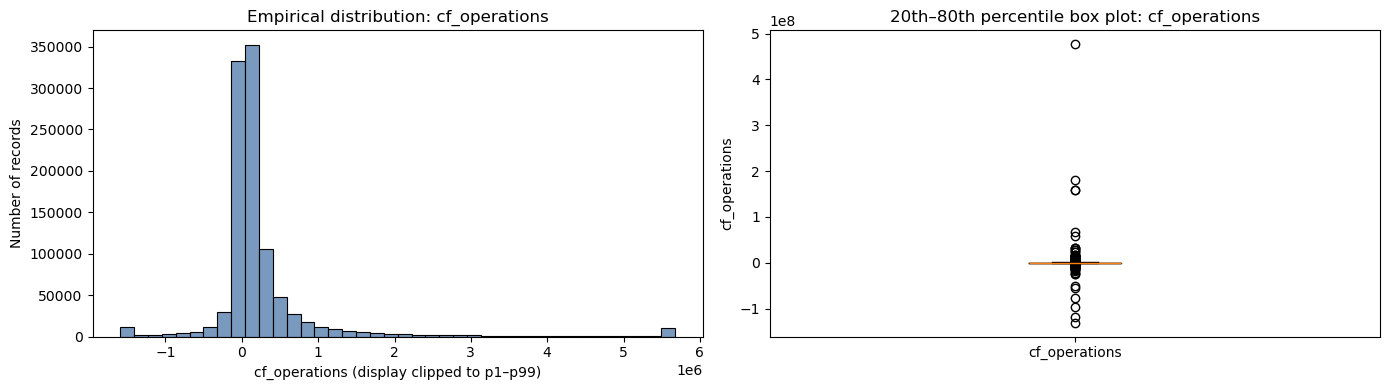

Display histogram is clipped to p1–p99; modified-Tukey outlier fences: [-4.841e+05, 7.92e+05].


**5. Additional diagnostic: median and missingness by fiscal year**

,n_observed,pct_missing,median
fs_year,,,
2007,144499,0.02,94326.0
2008,161852,0.01,77259.0
2009,171108,0.02,68180.0
2010,175396,0.00,74839.0
2011,184970,0.00,74797.0
2012,185639,0.00,71435.0


In [10]:
# Full report for every raw column. This deliberately excludes only the exported CSV index.
for column in RAW_COLUMNS:
    show_raw_column_eda(column)

#### prof_operations

Operating profit can be negative.

In [67]:
data[data["prof_financing"]<0]

,id,stmt_date,HQ_city,legal_struct,ateco_sector,def_date,fs_year,asst_intang_fixed,asst_tang_fixed,asst_fixed_fin,...,inc_extraord,taxes,profit,days_rec,ebitda,roa,roe,wc_net,margin_fin,cf_operations
10,1650282,2009-12-31,27.0,SRL,25.0,NaN,2009,462544.0,1522901.0,10620.0,...,-8324.0,607839.0,315491.0,67.64,1176527.0,6.26,15.75,1591746.0,7660.0,815473.0
12,1650282,2012-12-31,27.0,SRL,25.0,NaN,2012,14380.0,1151565.0,250370.0,...,89406.0,705141.0,407052.0,43.65,883926.0,7.22,18.90,2314967.0,737799.0,465865.0
14,1650282,2007-12-31,27.0,SRL,25.0,NaN,2007,881316.0,1128642.0,8231.0,...,62224.0,759122.0,506075.0,-3.19,1097368.0,6.29,16.18,1584139.0,1108702.0,868088.0
42,2890408,2010-12-31,40.0,SPA,43.0,NaN,2010,3008236.0,34897046.0,55060286.0,...,-264890.0,771400.0,901856.0,434.10,5924265.0,0.06,2.19,-3697856.0,-51809578.0,6674297.0
148,8010217,2009-12-31,21.0,SPA,68.0,NaN,2009,628171.0,1017927.0,313887.0,...,6036.0,-1290873.0,-1124050.0,33.82,-564984.0,-11.19,NaN,-1050498.0,-1595340.0,-842585.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1023516,80007460233,2007-12-31,23.0,SRL,70.0,NaN,2007,10811.0,530727.0,163984.0,...,17950.0,84215.0,4015.0,NaN,179484.0,4.54,0.30,616125.0,630685.0,41614.0
1023523,80047710639,2012-12-31,63.0,SRL,41.0,NaN,2012,222886.0,890352.0,27074.0,...,160855.0,80319.0,51196.0,NaN,58301.0,0.06,6.79,73028.0,-386344.0,95729.0
1023526,80186210581,2011-12-31,58.0,SRL,85.0,NaN,2011,154798.0,104070.0,159825.0,...,43541.0,-645002.0,-645002.0,NaN,-153640.0,-5.10,NaN,501329.0,NaN,-613176.0
1023530,81000950469,2008-12-31,46.0,SPA,38.0,NaN,2008,845327.0,16546242.0,1730717.0,...,-631177.0,-2564533.0,-2117006.0,248.81,195948.0,-2.36,-26.09,1976009.0,-11008788.0,-1241853.0


#### Goodwill

Goodwill is defined as the capacity of an undertaking to generate profits to a greater extent than normal, ie., the higher value achieved by its assets as a whole compared with the sum of the values of each individual asset, by virtue of the organisation of the goods and/or services in a process that is efficient and able to generate profits.

It CAN be negative.

Source: https://www.legal500.com/intelligence/italy/accounting-and-audit/goodwill-in-italy

In [69]:
data[data['goodwill']<0][["id", "stmt_date", "goodwill"]].sort_values(by="stmt_date", ascending=False)

,id,stmt_date,goodwill
3,520288,2012-12-31,-32223.0
225,12050639,2012-12-31,-169.0
691,32890287,2012-12-31,-89751.0
829,37200946,2012-12-31,-44641.0
921,39970314,2012-12-31,-164406.0
...,...,...,...
1023237,9580710011,2007-12-31,-2632.0
1023245,9598081009,2007-12-31,-2463.0
1023465,12250920159,2007-12-31,-2439943.0
1023477,12825290153,2007-12-31,-50239.0


#### inc_financing

Section C of the Structure and Contents of Italian Financial **“Proventi e oneri finanziari”**: financial income and financial charges.

The document breaks it into:

- **15 — Income from equity investments**
- **16 — Other financial income**, including income from:
  - fixed-asset receivables,
  - fixed-asset securities,
  - current-asset securities,
  - other sources, including group-company income
- **17 — Interest and other financial charges**
- **17bis — Foreign-exchange gains and losses**

The total for Section C is: Section C total = 15 + 16 - 17 + 17bis


In [70]:
data[data['inc_financing']<0][["id", "stmt_date", "inc_financing"]].sort_values(by="stmt_date", ascending=False)

,id,stmt_date,inc_financing
3,520288,2012-12-31,-11063.0
12,1650282,2012-12-31,-129048.0
22,2040061,2012-12-31,-46771.0
34,2540151,2012-12-31,-24320.0
40,2890408,2012-12-31,-2560456.0
...,...,...,...
1023506,13471220155,2007-12-31,-228513.0
1023511,80006470274,2007-12-31,-188972.0
1023533,81000950469,2007-12-31,-480189.0
1023539,90007390041,2007-12-31,-40.0


#### exp_financing

Why is exp financing negative tho?

In [5]:
data[data['prof_financing']<0][["id", "stmt_date", "prof_financing"]].sort_values(by="stmt_date", ascending=False)

,id,stmt_date,prof_financing
12,1650282,2012-12-31,-80330.0
634,30810311,2012-12-31,-17358.0
777,35670074,2012-12-31,-75000.0
818,37070323,2012-12-31,-1033.0
932,39990213,2012-12-31,-335936.0
...,...,...,...
1022610,7125440581,2007-12-31,-4643.0
1022775,7610810017,2007-12-31,-25766.0
1022865,8020881002,2007-12-31,-22825.0
1022909,8187670586,2007-12-31,-39418.0


### Who is the outlier? 